# Comparing branch length estimates between skyline / constant coalescent prior

In [1]:
from Bio import Nexus, Phylo, SeqIO
from collections import defaultdict
from io import StringIO

import matplotlib.pyplot as plt
from matplotlib import gridspec

import seaborn as sns

import pandas as pd
import numpy as np

import re
from pathlib import Path

from itertools import combinations

from evaluation_helpers import *

## Branch length errors

We measure branch length accuracy at two levels: the length of the whole tree and the lengths of individual branches. In all plots, each grey dot is one replicate (one simulated tree). The coloured dot is the median across replicates, and the vertical bar is the 95 % HPD interval across replicates. The two inference models are shown side by side for each mutation signal (low, medium, high): constant-size coalescent (blue) and Bayesian skyline (purple).                                                                                                                                                                                         
### 1. Total tree length
For each replicate, we sum all branch lengths (root excluded) in every posterior tree sample. We compare this total with the total length of the true simulated tree, $L_\text{true}$, as the absolute relative error
$|L_\text{post} - L_\text{true}| / L_\text{true}$. The value plotted per replicate is the median of this error over the posterior samples.

This measures whether the prior stretches or compresses the tree as a whole. Errors on individual branches can cancel out here, for example when some branches are too long and others too short.

### 2. Median per-branch error
For each replicate, we compute the relative error $(b_\text{post} - b_\text{true}) / b_\text{true}$ of every branch (root excluded) in every posterior sample. Branches are matched to the true tree by node, which works
because the topology is fixed. All these values, across branches and posterior samples, are pooled, and the plotted value per replicate is their median.

- The **relative error** (`bl_rel_error_median`) shows systematic bias. Positive values mean branches are overestimated, negative values mean they are underestimated.
- The **absolute relative error** (`bl_abs_rel_error_median`) shows typical accuracy regardless of direction. Errors in opposite directions don't cancel, so this is usually larger than the total-tree-length error.

**Difference between priors**:
In the single-scenario plots (`show_diff=True`), the green column on the right axis shows the relative difference between the two priors' errors per replicate: $(\text{err}_\text{const} - \text{err}_\text{sky}) /
\text{err}_\text{sky}$. Values above 0 mean the constant-size coalescent prior gives a larger error than the skyline prior. With `print_results=True`, the medians and HPD intervals of each group are printed.

### 3. HPD coverage of branch lengths
Low point errors alone don't show whether the posterior uncertainty is reliable. For every branch (root excluded) in every replicate, we compute the 95 % HPD interval of its posterior branch length. We then record whether
the true branch length lies inside it (`constcoal_bl_inside_ci`, `skyline_bl_inside_ci`).

- **Coverage table:** the fraction of branches whose true length lies inside the 95 % HPD, pooled over all branches and replicates. It is given per population model, mutation signal, sampling scheme and prior. For a
well-calibrated posterior this should be close to 95 %. Lower values mean the posterior is overconfident, often because it is confidently biased.
- **Coverage heatmaps** (one per sampling scheme): each panel is one scenario (population model × mutation signal). It is a 2×2 contingency table showing, for each branch, whether the true value is inside the HPD under
both priors, under only one of them, or under neither. Entries are percentages of all branches in that scenario. The off-diagonal cells show where one prior captures the truth and the other does not.

In [2]:
#tree_metrics_combined = load_node_errors("../results/run1/evaluation")
#tree_metrics_combined.to_csv("../results/run1/evaluation/all_node_info.csv", sep = "\t", index = False)
# warning comes from nan values in the boolean columns bl_inside_ci, also height_inside_ci columns contain nan values

tree_metrics_combined = pd.read_csv("../results/run1/evaluation/all_node_info.csv", sep = "\t")

df_pop_info = load_pop_summaries("../results/run1/evaluation")
traj_df = load_pop_trajectories("../results/run1/evaluation")
df_pop_info.head()

,sampling,population_model,mutation_signal,tree_index,skyline_times,skyline_medians,skyline_lowers,skyline_uppers,skyline_samples,skyline_times_samples,...,skyline_height_rel_error_hpd_lower,skyline_height_rel_error_hpd_upper,skyline_height_abs_rel_error_median,skyline_height_abs_rel_error_hpd_lower,skyline_height_abs_rel_error_hpd_upper,present_pop_size,growth_rate,bottleneck_size,bottleneck_start,bottleneck_end
0,independenthomochronous,bottleneck,high,0,"[1.4766475121491567, 1.936933946825775, 2.7924...","[1539.7790587904333, 364.72642362756756, 568.9...","[788.7031515101185, 48.09414458616408, 204.320...","[2442.7797527796133, 1009.5813460576722, 1178....",0 1 2 ...,0 1 2 3 ...,...,-0.999780,1.976007,0.219272,1.613809e-06,1.975971,1000,NaN,100.0,20.0,23.0
1,independenthomochronous,bottleneck,high,1,"[0.7972796095147032, 2.283983509613563, 3.3353...","[870.183332578285, 1227.7435827097408, 662.569...","[341.30491645982335, 322.8526958585132, 110.90...","[1651.6094209640742, 2109.52343929743, 1507.32...",0 1 2 ...,0 1 2 3 ...,...,-0.999972,1.878092,0.217775,1.257787e-06,1.878092,1000,NaN,100.0,20.0,23.0
2,independenthomochronous,bottleneck,high,2,"[0.6745245198007979, 1.4017453323986047, 2.497...","[728.75977974291, 591.7736735048368, 657.65410...","[254.0855896756848, 96.85047836117484, 162.428...","[1396.313045847564, 1328.4629454806836, 1368.1...",0 1 2 ...,0 1 2 3 ...,...,-0.999985,1.808220,0.236929,3.309909e-06,1.808220,1000,NaN,100.0,20.0,23.0
3,independenthomochronous,bottleneck,high,3,"[1.0983578731604666, 3.140976440498889, 4.6544...","[1226.2631616243966, 1658.709338766412, 955.15...","[528.0302082404304, 425.2173202434592, 178.501...","[2201.8022083351498, 2822.6265810398577, 2064....",0 1 2 ...,0 1 2 3 ...,...,-0.999905,1.811305,0.218756,7.694055e-07,1.811290,1000,NaN,100.0,20.0,23.0
4,independenthomochronous,bottleneck,high,4,"[1.2059733820469773, 2.060165011666868, 3.3035...","[1289.081011837042, 691.6623577699729, 774.274...","[590.3474220426203, 110.90377012142191, 158.90...","[2249.5010188577944, 1614.283109901542, 1543.0...",0 1 2 ...,0 1 2 3 ...,...,-0.999917,1.897541,0.226753,6.065042e-07,1.897541,1000,NaN,100.0,20.0,23.0


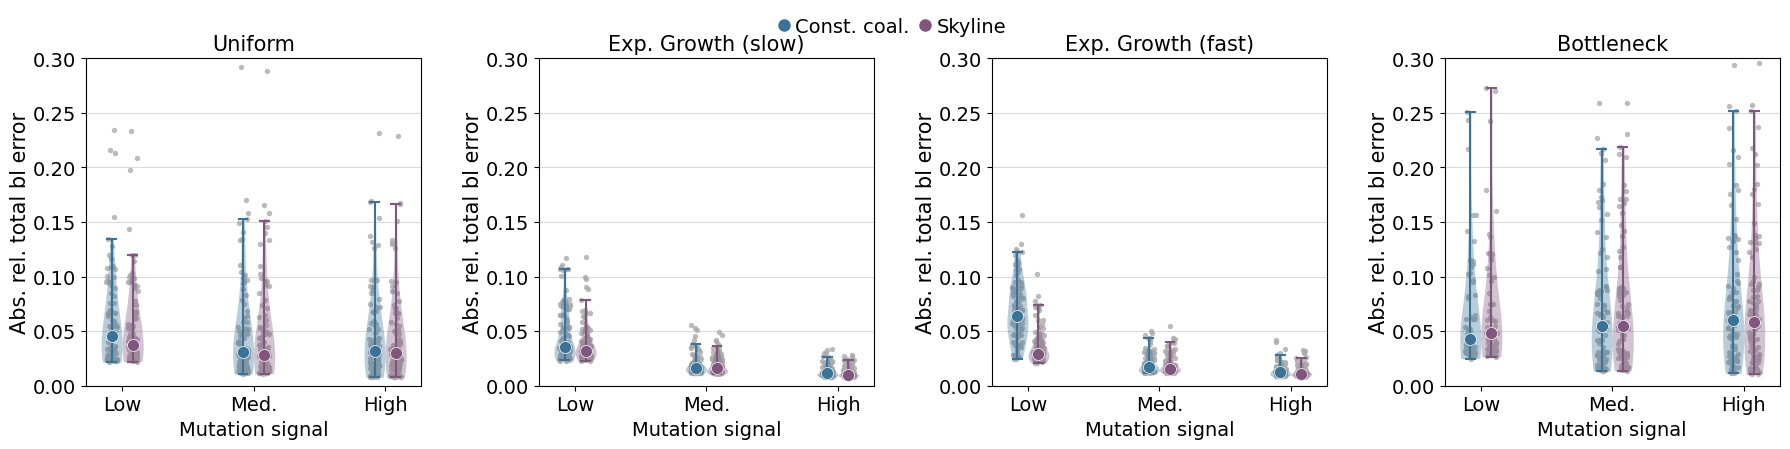

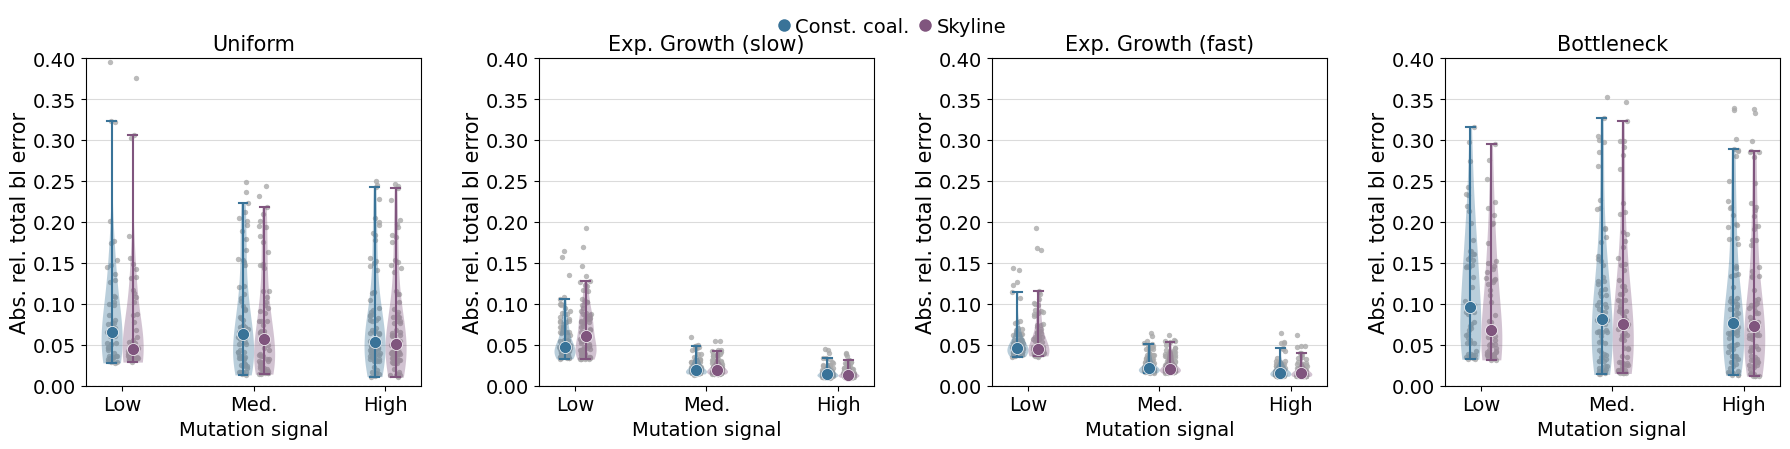

In [ ]:
# total branch length error plots
# linear constant / heterochronous sampling
plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant',
                        y_col="total_bl_abs_rel_error_median", y_label="Abs. rel. total bl error", y_range=(0, 0.3),
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/branch_length/total_branch_length/abs_rel_error_totalbl_linearconstant_violin.pdf", violin = True)

# homochronous sampling
plot_error_by_mutsig(df_pop_info, sampling = 'independenthomochronous',
                        y_col="total_bl_abs_rel_error_median", y_label="Abs. rel. total bl error", y_range=(0, 0.4),
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/branch_length/total_branch_length/abs_rel_error_totalbl_independenthomochronous_violin.pdf", violin = True)

uniform         Const. coal. low  mutsig  n=100  median=0.4734  95% HPD=(0.4491, 0.4893)
uniform         Const. coal. med  mutsig  n=100  median=0.2968  95% HPD=(0.2744, 0.3159)
uniform         Const. coal. high mutsig  n= 98  median=0.2241  95% HPD=(0.2067, 0.2425)
uniform         Skyline      low  mutsig  n=100  median=0.4777  95% HPD=(0.4527, 0.4986)
uniform         Skyline      med  mutsig  n=100  median=0.2982  95% HPD=(0.2732, 0.3138)
uniform         Skyline      high mutsig  n= 98  median=0.2248  95% HPD=(0.2085, 0.2452)
uniform         Const-Sky rel. diff.   low  mutsig  n=100  median=-0.009845  95% HPD=(-0.02947, 0.006735)
uniform         Const-Sky rel. diff.   med  mutsig  n=100  median=-0.005032  95% HPD=(-0.01491, 0.007144)
uniform         Const-Sky rel. diff.   high mutsig  n= 98  median=-0.004263  95% HPD=(-0.01374, 0.008953)


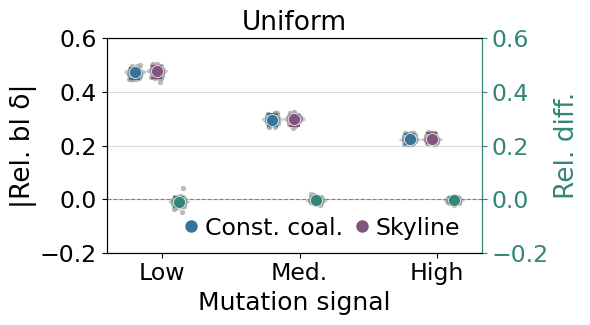

expgrowthfast   Const. coal. low  mutsig  n= 98  median=0.524  95% HPD=(0.5026, 0.5512)
expgrowthfast   Const. coal. med  mutsig  n= 99  median=0.3474  95% HPD=(0.325, 0.3654)
expgrowthfast   Const. coal. high mutsig  n=100  median=0.2662  95% HPD=(0.2504, 0.2813)
expgrowthfast   Skyline      low  mutsig  n= 98  median=0.5131  95% HPD=(0.4863, 0.5352)
expgrowthfast   Skyline      med  mutsig  n= 99  median=0.3433  95% HPD=(0.3245, 0.3658)
expgrowthfast   Skyline      high mutsig  n=100  median=0.2643  95% HPD=(0.2452, 0.2768)
expgrowthfast   Const-Sky rel. diff.   low  mutsig  n= 98  median=0.02218  95% HPD=(-0.01262, 0.05205)
expgrowthfast   Const-Sky rel. diff.   med  mutsig  n= 99  median=0.0087  95% HPD=(-0.01355, 0.03685)
expgrowthfast   Const-Sky rel. diff.   high mutsig  n=100  median=0.005552  95% HPD=(-0.01237, 0.02361)


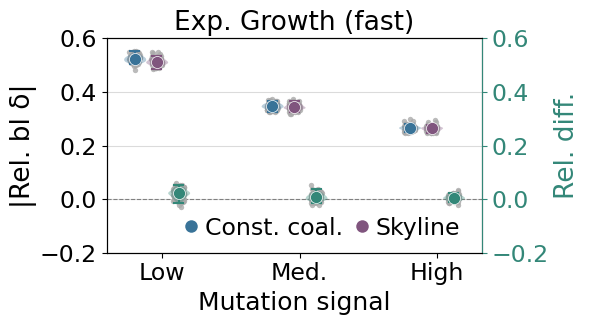

expgrowthslow   Const. coal. low  mutsig  n=100  median=0.486  95% HPD=(0.4637, 0.511)
expgrowthslow   Const. coal. med  mutsig  n=100  median=0.3067  95% HPD=(0.29, 0.3243)
expgrowthslow   Const. coal. high mutsig  n=100  median=0.2326  95% HPD=(0.2162, 0.2442)
expgrowthslow   Skyline      low  mutsig  n=100  median=0.4889  95% HPD=(0.4635, 0.5141)
expgrowthslow   Skyline      med  mutsig  n=100  median=0.3076  95% HPD=(0.2888, 0.3261)
expgrowthslow   Skyline      high mutsig  n=100  median=0.2319  95% HPD=(0.2171, 0.2445)
expgrowthslow   Const-Sky rel. diff.   low  mutsig  n=100  median=-0.001589  95% HPD=(-0.02555, 0.01935)
expgrowthslow   Const-Sky rel. diff.   med  mutsig  n=100  median=-0.001283  95% HPD=(-0.02388, 0.01512)
expgrowthslow   Const-Sky rel. diff.   high mutsig  n=100  median=-0.0005883  95% HPD=(-0.01951, 0.01445)


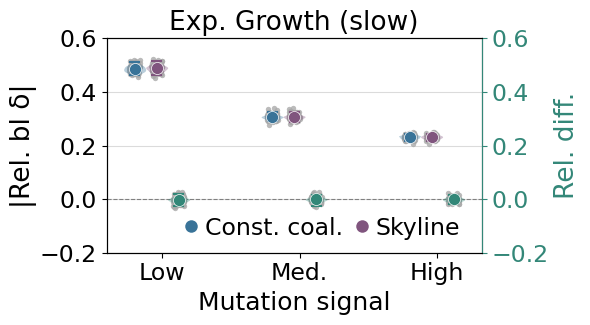

bottleneck      Const. coal. low  mutsig  n= 71  median=0.5492  95% HPD=(0.5273, 0.5771)
bottleneck      Const. coal. med  mutsig  n= 94  median=0.3782  95% HPD=(0.3582, 0.4025)
bottleneck      Const. coal. high mutsig  n= 97  median=0.2959  95% HPD=(0.2749, 0.3148)
bottleneck      Skyline      low  mutsig  n= 71  median=0.5149  95% HPD=(0.481, 0.5441)
bottleneck      Skyline      med  mutsig  n= 94  median=0.3444  95% HPD=(0.3173, 0.3701)
bottleneck      Skyline      high mutsig  n= 97  median=0.271  95% HPD=(0.2508, 0.2934)
bottleneck      Const-Sky rel. diff.   low  mutsig  n= 71  median=0.07244  95% HPD=(0.02821, 0.1152)
bottleneck      Const-Sky rel. diff.   med  mutsig  n= 94  median=0.09519  95% HPD=(0.03746, 0.1385)
bottleneck      Const-Sky rel. diff.   high mutsig  n= 97  median=0.08982  95% HPD=(0.04539, 0.1462)


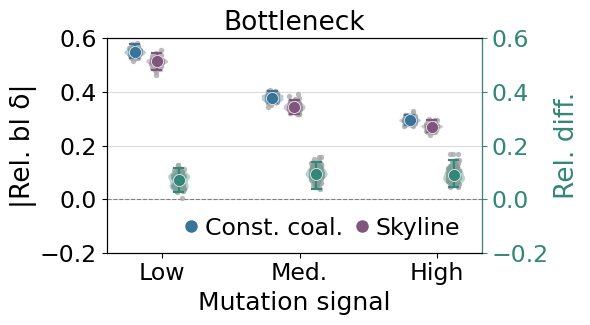

In [ ]:
# absolute relative branch length errors considering all branches in all replicates as well as the relative difference between the constant-size coalescent and skyline prior
# the plots show per replicate medians as well as an overall median inferred from these
# heterochronous sampling

plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant', print_results=True,
                        y_col="bl_abs_rel_error_median", y_label="|Rel. bl δ|", y_range=(-0.2, 0.6),
                        pop_models=['uniform'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range=(-0.2, 0.6),
                        show_pop_model_labels = True, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/branch_length/median_error/median_abs_rel_bl_error_uniform_linearconstant.pdf", violin = True)

plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant', print_results=True,
                        y_col="bl_abs_rel_error_median", y_label="|Rel. bl δ|", y_range=(-0.2, 0.6),
                        pop_models=['expgrowthfast'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range=(-0.2, 0.6),
                        show_pop_model_labels = True, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/branch_length/median_error/median_abs_rel_bl_error_expgrowthfast_linearconstant.pdf", violin = True)

plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant', print_results=True,
                        y_col="bl_abs_rel_error_median", y_label="|Rel. bl δ|", y_range=(-0.2, 0.6),
                        pop_models=['expgrowthslow'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range=(-0.2, 0.6),
                        show_pop_model_labels = True, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/branch_length/median_error/median_abs_rel_bl_error_expgrowthslow_linearconstant.pdf", violin = True)

plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant', print_results=True,
                        y_col="bl_abs_rel_error_median", y_label="|Rel. bl δ|", y_range=(-0.2, 0.6),
                        pop_models=['bottleneck'], figsize=(6,3.5), legend_inside=True,
                        show_diff=True, diff_mode="relative", diff_y_range=(-0.2, 0.6),
                        show_pop_model_labels = True, label_fontsize=18, tick_fontsize=17, legend_fontsize=17,
                        title="", save_path="../figures/branch_length/median_error/median_abs_rel_bl_error_bottleneck_linearconstant.pdf", violin = True)

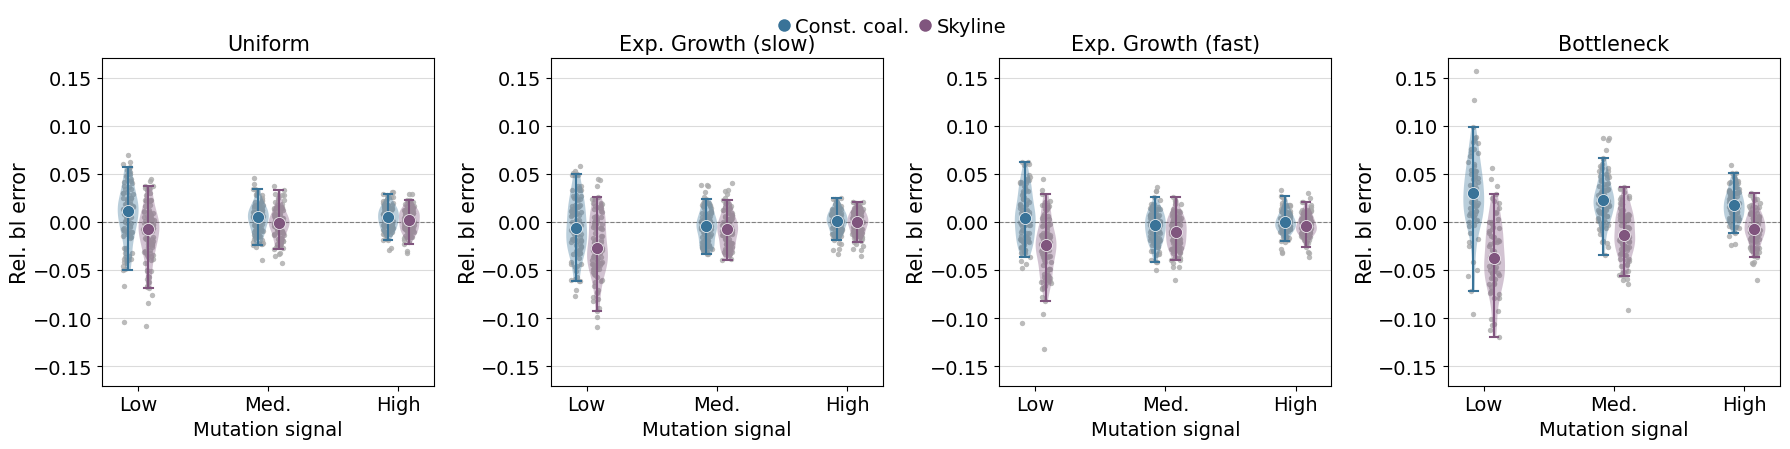

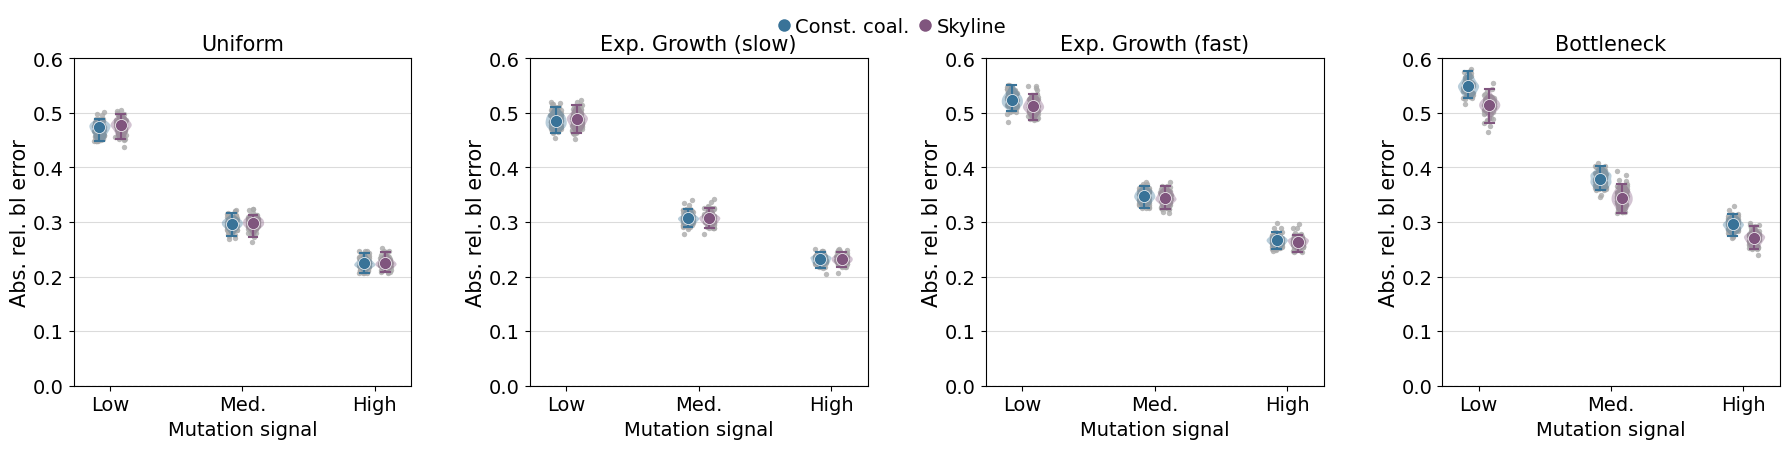

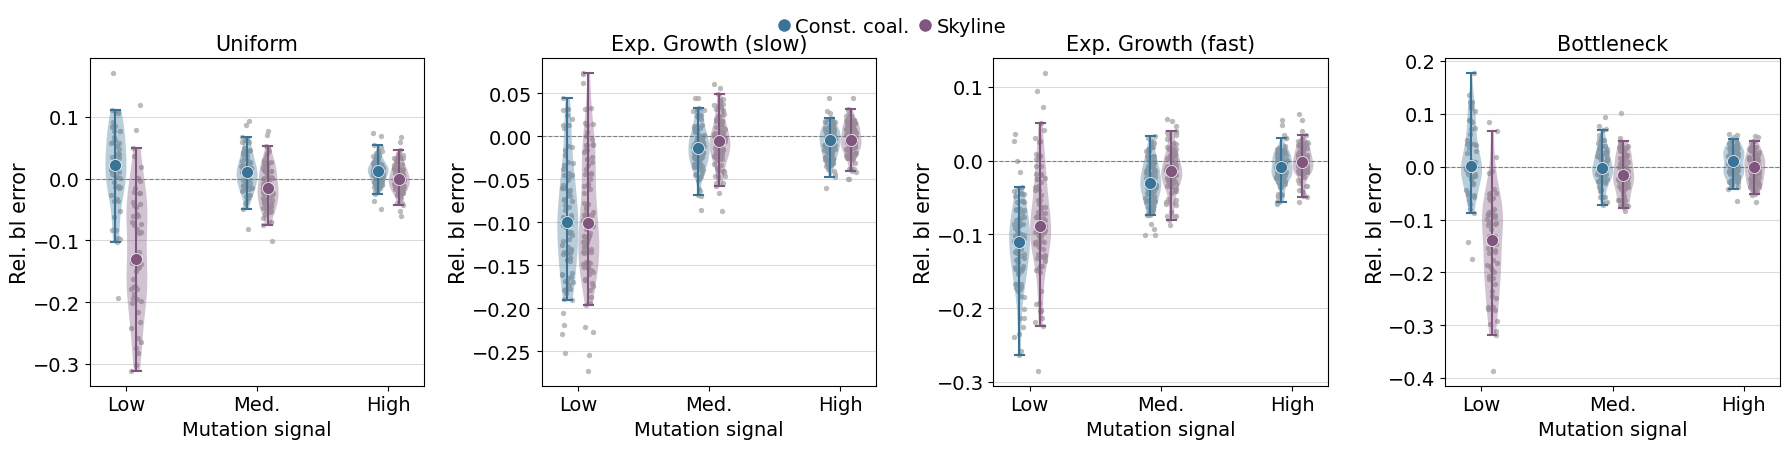

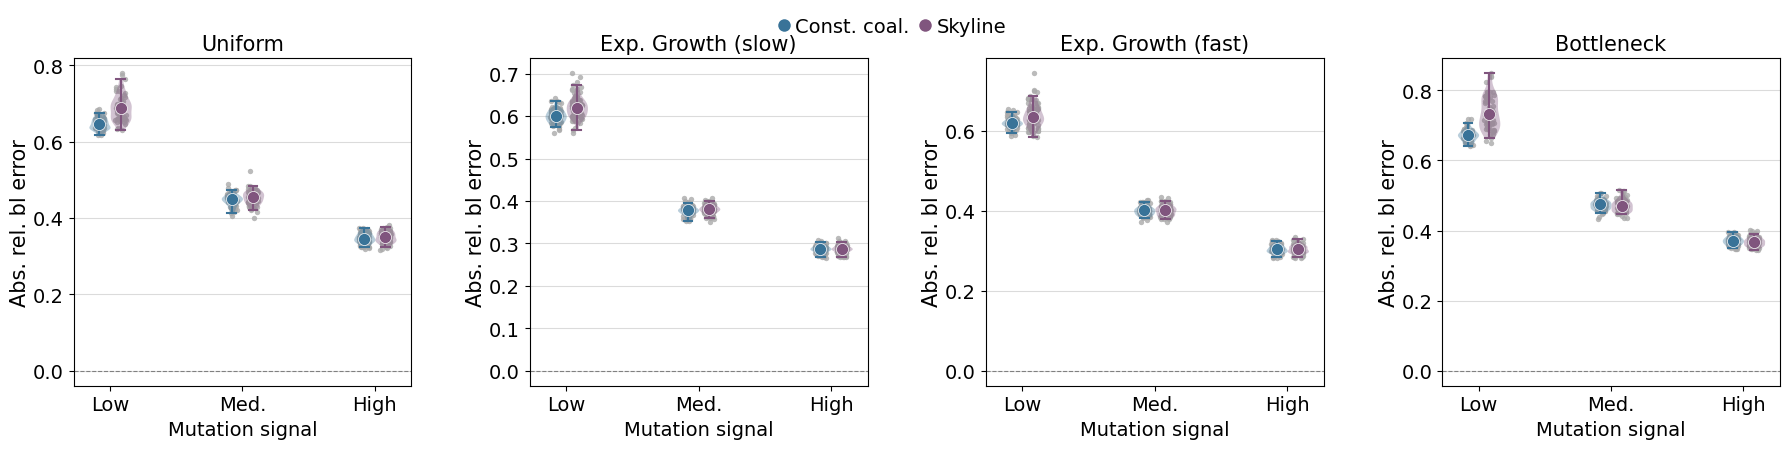

In [ ]:
# rel. and abs. rel branch lenghth errors for all population models and both sampling schemes

# heterochronous sampling
plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant',
                        y_col="bl_rel_error_median", y_label="Rel. bl error", y_range=(-0.17, 0.17),
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/branch_length/median_error/median_rel_bl_error_linearconstant.pdf", violin = True)

plot_error_by_mutsig(df_pop_info, sampling = 'linearconstant',
                        y_col="bl_abs_rel_error_median", y_label="Abs. rel. bl error", y_range=(0, 0.6),
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path="../figures/branch_length/median_error/median_abs_rel_bl_error_linearconstant.pdf", violin = True)

# homochronous sampling
plot_error_by_mutsig(df_pop_info, sampling = 'independenthomochronous',
                        y_col="bl_rel_error_median", y_label="Rel. bl error", y_range=None,
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path=None, violin = True)

plot_error_by_mutsig(df_pop_info, sampling = 'independenthomochronous',
                        y_col="bl_abs_rel_error_median", y_label="Abs. rel. bl error", y_range=None,
                        pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                        title="", save_path=None, violin = True)

In [ ]:
# percentage of true branch length inside estimated 95% HPD intervals by condition and model

print("Percentage of branch length estimates inside 95% HPD by condition and model:")
display(tree_metrics_combined.groupby(['population_model', 'mutation_signal', 'sampling']).apply(
    lambda g: pd.Series({
        "constcoal": g["constcoal_bl_inside_ci"].mean(),
        "skyline":   g["skyline_bl_inside_ci"].mean(),
    }), include_groups=False
).reset_index())

Percentage of branch length estimates inside 95% HPD by condition and model:


,population_model,mutation_signal,sampling,constcoal,skyline
0,bottleneck,high,independenthomochronous,0.937199,0.935768
1,bottleneck,high,linearconstant,0.938449,0.934037
2,bottleneck,low,independenthomochronous,0.937930,0.923049
3,bottleneck,low,linearconstant,0.933847,0.929772
4,bottleneck,med,independenthomochronous,0.933418,0.931859
5,bottleneck,med,linearconstant,0.936245,0.932126
6,expgrowthfast,high,independenthomochronous,0.942054,0.942032
7,expgrowthfast,high,linearconstant,0.938489,0.940639
8,expgrowthfast,low,independenthomochronous,0.915221,0.934000
9,expgrowthfast,low,linearconstant,0.932037,0.936473


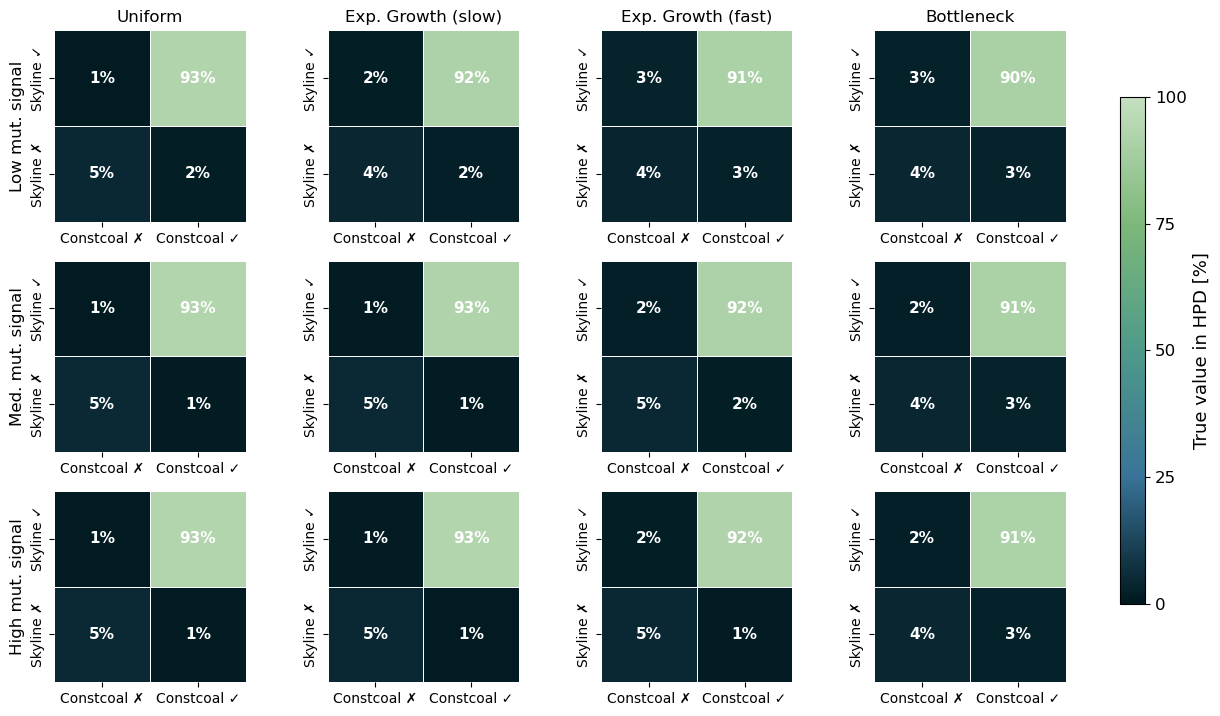

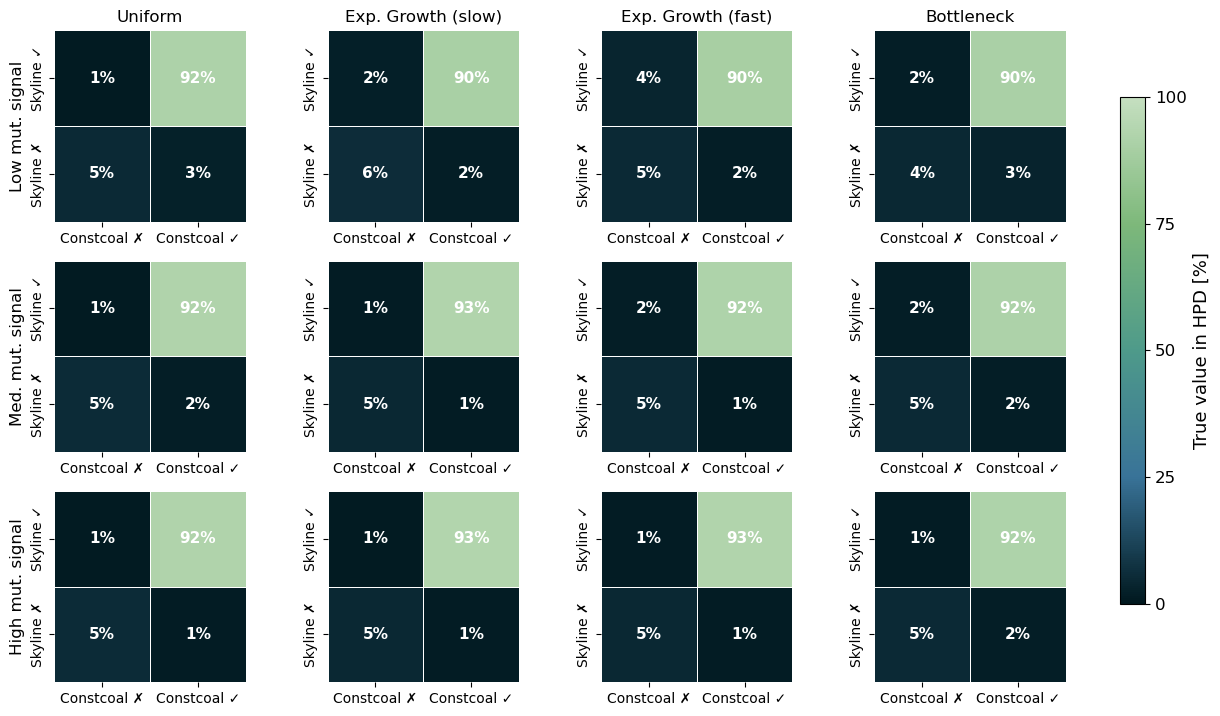

In [ ]:
# heterochronous sampling
plot_ci_coverage_heatmap_nodes(tree_metrics_combined, mode="bl", sampling='linearconstant', title = "", save_path= "../figures/branch_length/coverage_heatmaps/hpd_coverage_heatmap_bl_linearconstant.pdf", cbar_label = "True value in HPD [%]")

# homochronous sampling
plot_ci_coverage_heatmap_nodes(tree_metrics_combined, mode="bl", sampling='independenthomochronous', title = "", save_path= "../figures/branch_length/coverage_heatmaps/hpd_coverage_heatmap_bl_independenthomochronous.pdf", cbar_label = "True value in HPD [%]")

## Branch length errors through time

The summaries above pool all branches in a tree, which hides *when* in the past the errors occur. To link branch length errors to the population size history, we group branches into time bins by the **true height of their 
younger node**. Bin edges are $[0, w, 2w, \dots, \text{cutoff}]$, plus one final bin for everything older
than the cutoff.

`compute_time_bins.py` produces two kinds of summaries per bin, for both priors:
- **Pooled** (`load_time_bins`): median and 95 % HPD over all observations in the bin, i.e. all posterior samples × all replicates × all branches that end in the bin.
- **Per replicate** (`load_time_bins_per_tree`): the same summary computed separately for each replicate. These values are drawn as the faint background dots.

Besides the branch length errors, each bin holds the error in the population size estimate at the time each branch ends (node closer to the present). We compare the estimated $N_e$ at the true node height (the skyline interval covering that time, or
the single constant-coalescent estimate) with the true $N_e$ from the simulation. We express this as the relative error in the coalescent rate $1/N_e$, because the rate is what scales expected branch lengths under the coalescent. For each analysis we choose the bin width and cutoff to match the time scale of the scenario. For the bottleneck we use fine 1-year bins up to 50 years. For uniform and exponential growth we use 5-year bins up to 100–400 years. Bins with fewer than `min_nodes_per_bin` branches are not shown.

### Bottleneck: population trajectory and branch length error
For the bottleneck scenario, each panel pairs two plots that share the same time axis:
- **Top:** the true population size trajectory (red), the inferred skyline trajectory (purple) and the constant-coalescent estimate (blue), each shown as the median across replicates with a 95 % HPD band. Under heterochronous sampling, the dots on the strip mark the skyline change points of the individual replicates, and the arrow marks the sampling period (0–30 years). Both are omitted under homochronous sampling, where all tips are sampled at the present.
- **Bottom:** the relative branch length error $(b_\text{post} - b_\text{true}) / b_\text{true}$ per 1-year bin, as the pooled median (with 95 % HPD bars in the full versions). The faint dots are the per-replicate medians.

### Uniform and exponential growth: population size error vs. branch length error
For the scenarios with smooth trajectories we plot the two errors against each other. Each point is one time bin (5-year bins, up to 100 years before the present):
- **x-axis:** relative error in the coalescent rate $1/N_e$ at the time each branch ends.
- **y-axis:** relative branch length error.
- **colour:** time of the bin (lower bound). Blue shades are the constant-size coalescent, red to purple shades are the skyline.

Error bars show the pooled 95 % HPD. The faint background dots are per-replicate medians.

In [26]:
# load all time binned data

# all pop. models
df_5_100 = load_time_bins("../results/run1/evaluation", bin_width=5, cutoff=100)
df_5_100_pertree = load_time_bins_per_tree("../results/run1/evaluation", bin_width=5, cutoff=100)
df_5_400 = load_time_bins("../results/run1/evaluation", bin_width=5, cutoff=400)

# only bottleneck
df_1_30 = load_time_bins("../results/run1/evaluation", bin_width=1, cutoff=30)
df_1_50 = load_time_bins("../results/run1/evaluation", bin_width=1, cutoff=50)
df_1_50_pertree = load_time_bins_per_tree("../results/run1/evaluation", bin_width=1, cutoff=50)

df_5_100.head()

,model,bin_lower,bin_upper,bin_center,n_nodes,n_trees,height_sim_median,height_sim_hpd_lower,height_sim_hpd_upper,bl_sim_median,...,bl_rel_error_hpd_lower,bl_rel_error_hpd_upper,bl_abs_rel_error_median,bl_abs_rel_error_hpd_lower,bl_abs_rel_error_hpd_upper,height_ci_coverage,bl_ci_coverage,sampling,population_model,mutation_signal
0,constcoal,0.0,5.0,1.919113,27649,80,1.919113,0.000550,4.637590,3.552204,...,-0.999999,3.269691,0.382799,1.591633e-08,3.269691,0.958295,0.940215,independenthomochronous,bottleneck,high
1,constcoal,5.0,10.0,7.030539,3387,80,7.030539,5.000251,9.601283,6.443333,...,-0.999997,3.311108,0.374601,4.107163e-07,3.311108,0.929731,0.943313,independenthomochronous,bottleneck,high
2,constcoal,10.0,15.0,12.110841,1906,80,12.110841,10.000196,14.642764,6.867935,...,-0.999997,3.112444,0.403249,1.429746e-07,3.112444,0.926023,0.940189,independenthomochronous,bottleneck,high
3,constcoal,15.0,20.0,17.229006,1274,80,17.229006,15.002455,19.724052,3.695498,...,-0.999995,3.846702,0.512435,3.224833e-07,3.846702,0.919152,0.956044,independenthomochronous,bottleneck,high
4,constcoal,20.0,25.0,21.041573,3107,80,21.041573,20.000183,22.884724,2.298588,...,-0.999995,14.948714,0.467990,7.171381e-08,14.948714,0.930801,0.962021,independenthomochronous,bottleneck,high


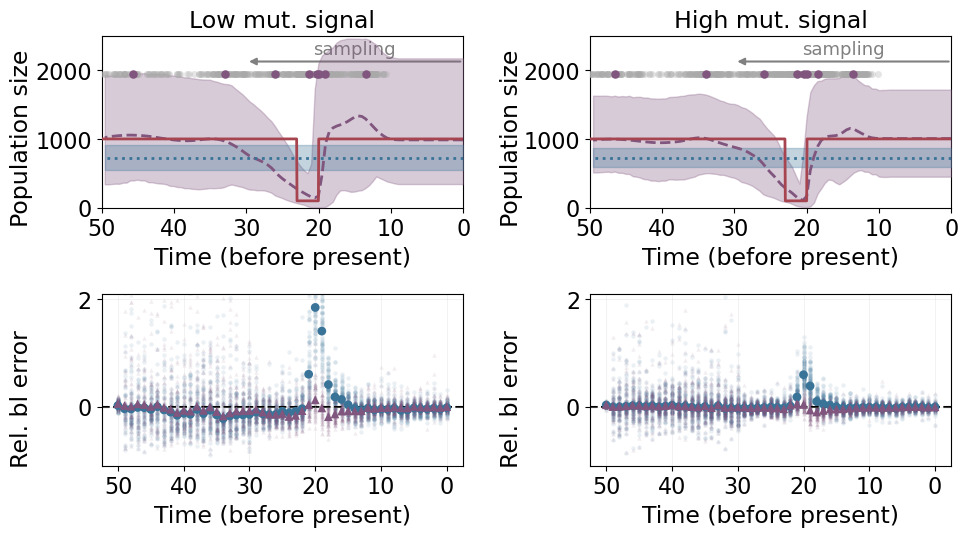

In [ ]:
# detailed view for heterochronous sampling with bottleneck population model

plot_combined_population_and_error(
      df_population=df_pop_info, trajectory_df = traj_df,
      df_time_bins=df_1_50,   # from load_time_bins(eval_dir, bin_width=10, cutoff=100)
      sampling="linearconstant",
      error_col="bl_rel_error_median",
      mutsigs = ['low', 'high'],
      pop_y_range=(0, 2500),
      error_y_range=(-1.1,2.1),
      min_nodes_per_bin = 20, time_col = "bin_lower",
      title="", x_label = "Time (before present)", error_y_label = "Rel. bl error",
      per_tree_df=df_1_50_pertree, raw_alpha = 0.1, errorbar_alpha = 0, jitter_width = 0, marker_edgecolor='none',
      save_path="../figures/branch_length/time_overview/bottleneck_blerror_popsize_linearconstant_small_50_lowhigh.pdf",
      ylabel_x_positions=[0.04, 0.53], error_ylabel_y_offset=-0.06,
      sampling_end_time=30,
      label_fontsize=17, tick_fontsize=16, legend_fontsize=17, sampling_fontsize=13, hspace = 0.5, wspace = 0.35, xticks = [0, 10, 20, 30, 40, 50], show_legend = False,
      show_changepoints=True, changepoint_dot_size=25, changepoint_grey_alpha=0.3, changepoint_y_frac = 0.78,
  )

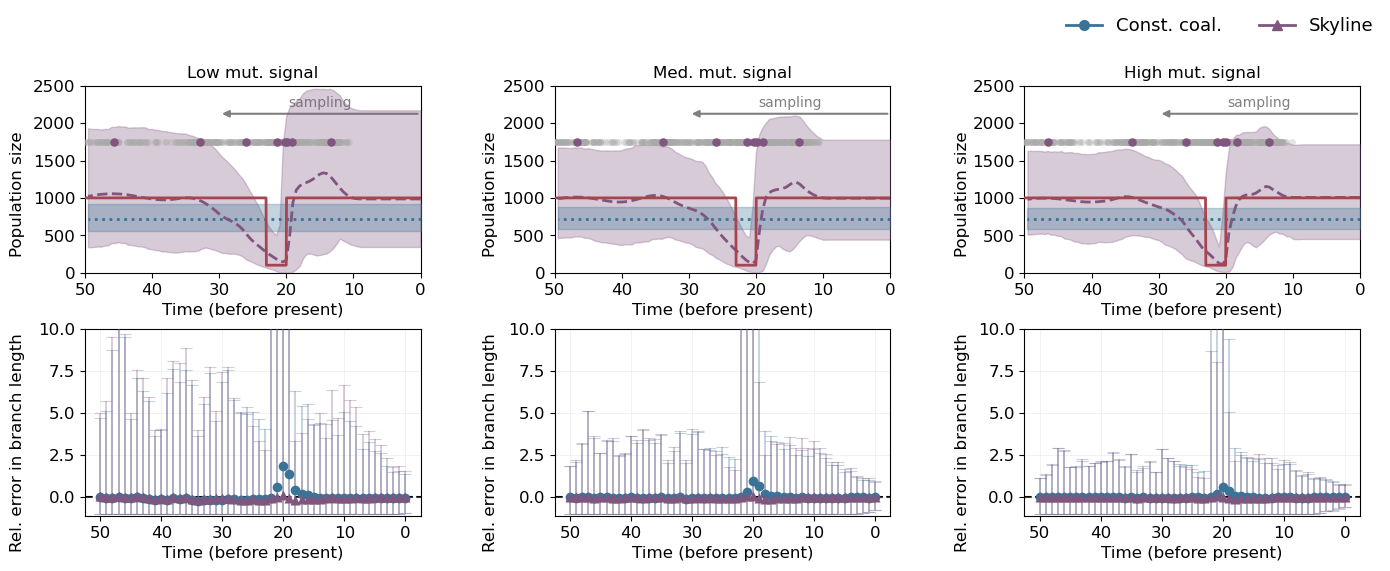

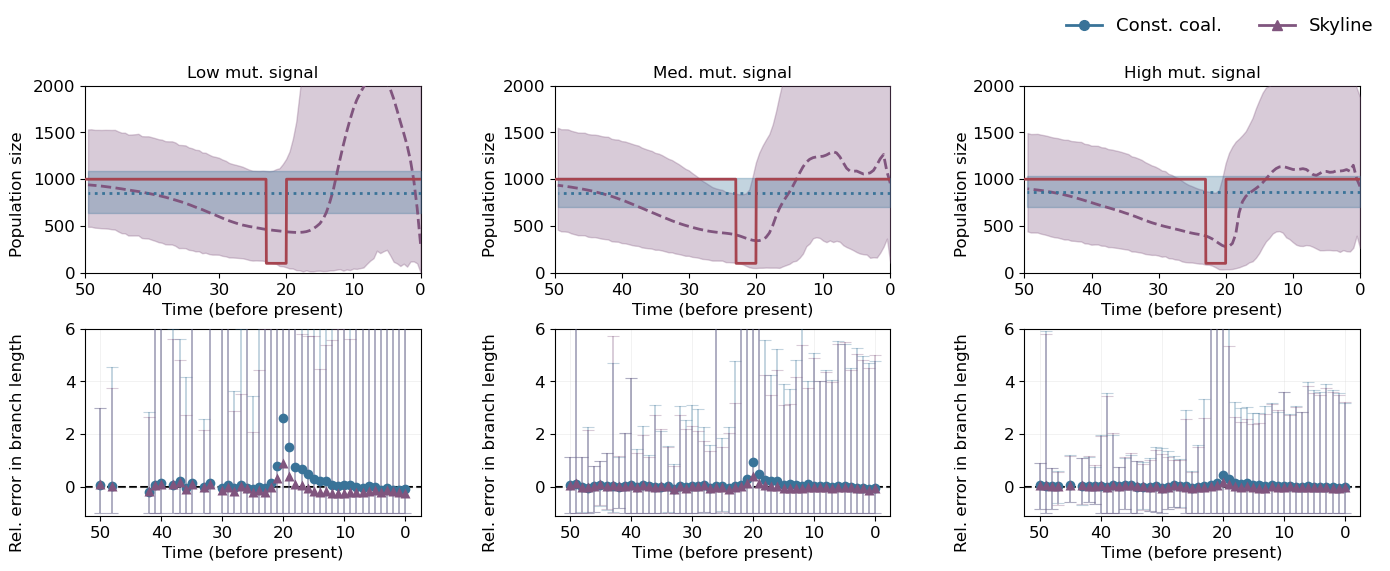

In [ ]:
# heterochronous sampling
plot_combined_population_and_error(
      df_population=df_pop_info, trajectory_df = traj_df,
      df_time_bins=df_1_50,   # from load_time_bins(eval_dir, bin_width=10, cutoff=100)
      sampling="linearconstant",
      error_col="bl_rel_error_median",
      pop_y_range=(0, 2500),
      error_y_range=(-1.1,10),
      min_nodes_per_bin = 20, time_col = "bin_lower",
      title="", x_label = "Time (before present)", error_y_label = "Rel. error in branch length",
      raw_alpha = 0.1, errorbar_alpha = 0.3, jitter_width = 0, marker_edgecolor='none',
      save_path="../figures/branch_length/time_overview/bottleneck_blerror_popsize_linearconstant_small_50_cis.pdf",
      ylabel_x_positions=[0.075, 0.39, 0.705], error_ylabel_y_offset=-0.06,
      sampling_end_time=30,
  )

# homochronous sampling
plot_combined_population_and_error(
      df_population=df_pop_info, trajectory_df = traj_df,
      df_time_bins=df_1_50,   # from load_time_bins(eval_dir, bin_width=10, cutoff=100)
      sampling="independenthomochronous",
      error_col="bl_rel_error_median",
      pop_y_range=(0, 2000),
      error_y_range=(-1.1,6),
      min_nodes_per_bin = 20, time_col = "bin_lower",
      title="", x_label = "Time (before present)", error_y_label = "Rel. error in branch length",
      raw_alpha = 0.1, errorbar_alpha = 0.3, jitter_width = 0, marker_edgecolor='none',
      save_path="../figures/branch_length/time_overview/bottleneck_blerror_popsize_independenthomochronous_small_50_cis.pdf",
      ylabel_x_positions=[0.075, 0.39, 0.705], error_ylabel_y_offset=-0.06,
      sampling_end_time=30,
  )

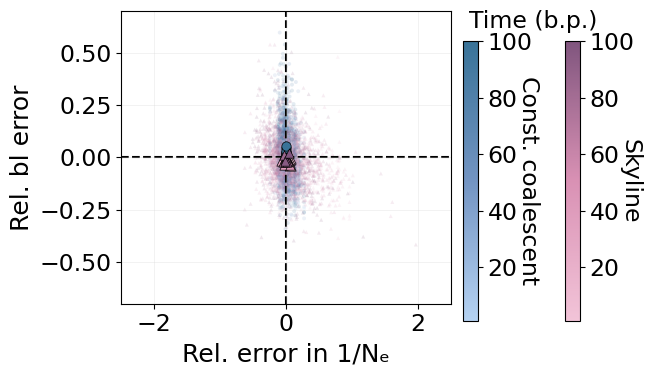

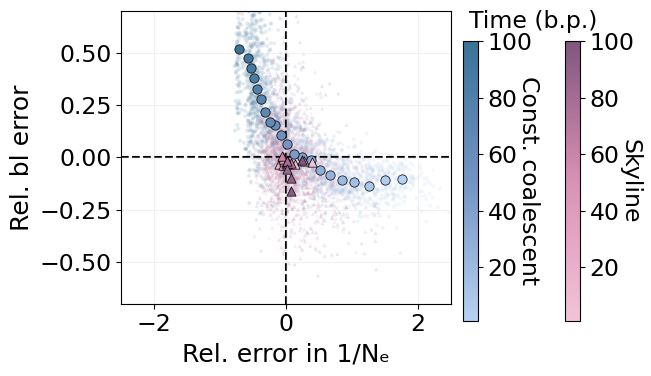

In [ ]:
# detailed view for heterochronous sampling low mutation signal
# uniform
plot_binned_error_timecoloring(df_5_100, per_tree_df = df_5_100_pertree, sampling="linearconstant",
                               x_col="rate_rel_error", y_col="bl_rel_error", time_col = 'bin_lower',
                               x_range=(-2.5,2.5), y_range=(-0.7, 0.7), figsize=(6,4),
                               x_label = "Rel. error in 1/Nₑ", y_label = "Rel. bl error", title = "",
                               cbar_label_constcoal= "Branch end time (bin lower bound) - Const. Coalescent", cbar_label_skyline="Branch end time (bin lower bound) - Skyline",
                               min_nodes_per_bin=10, pop_models=['uniform'], mutsigs=['low'], show_pop_model_labels = False, show_mutsig_labels = False,
                               label_fontsize=18, tick_fontsize=17, legend_fontsize=17, cbar_tick_fontsize = 17,
                               save_path="../figures/branch_length/time_popsize_scatter/bl_rate_error_linearconstant_pertreeuncertainty_uniform.pdf")

# fast exponential growth
plot_binned_error_timecoloring(df_5_100, per_tree_df = df_5_100_pertree, sampling="linearconstant",
                               x_col="rate_rel_error", y_col="bl_rel_error", time_col = 'bin_lower',
                               x_range=(-2.5,2.5), y_range=(-0.7, 0.7), figsize = (6,4),
                               x_label = "Rel. error in 1/Nₑ", y_label = "Rel. bl error", title = "",
                               cbar_label_constcoal= "Branch end time (bin lower bound) - Const. Coalescent", cbar_label_skyline="Branch end time (bin lower bound) - Skyline",
                               min_nodes_per_bin=10, pop_models=['expgrowthfast'], mutsigs=['low'], show_pop_model_labels = False, show_mutsig_labels = False,
                               label_fontsize=18, tick_fontsize=17, legend_fontsize=17, cbar_tick_fontsize = 17,
                               save_path="../figures/branch_length/time_popsize_scatter/bl_rate_error_linearconstant_pertreeuncertainty_expgrowthfast.pdf")

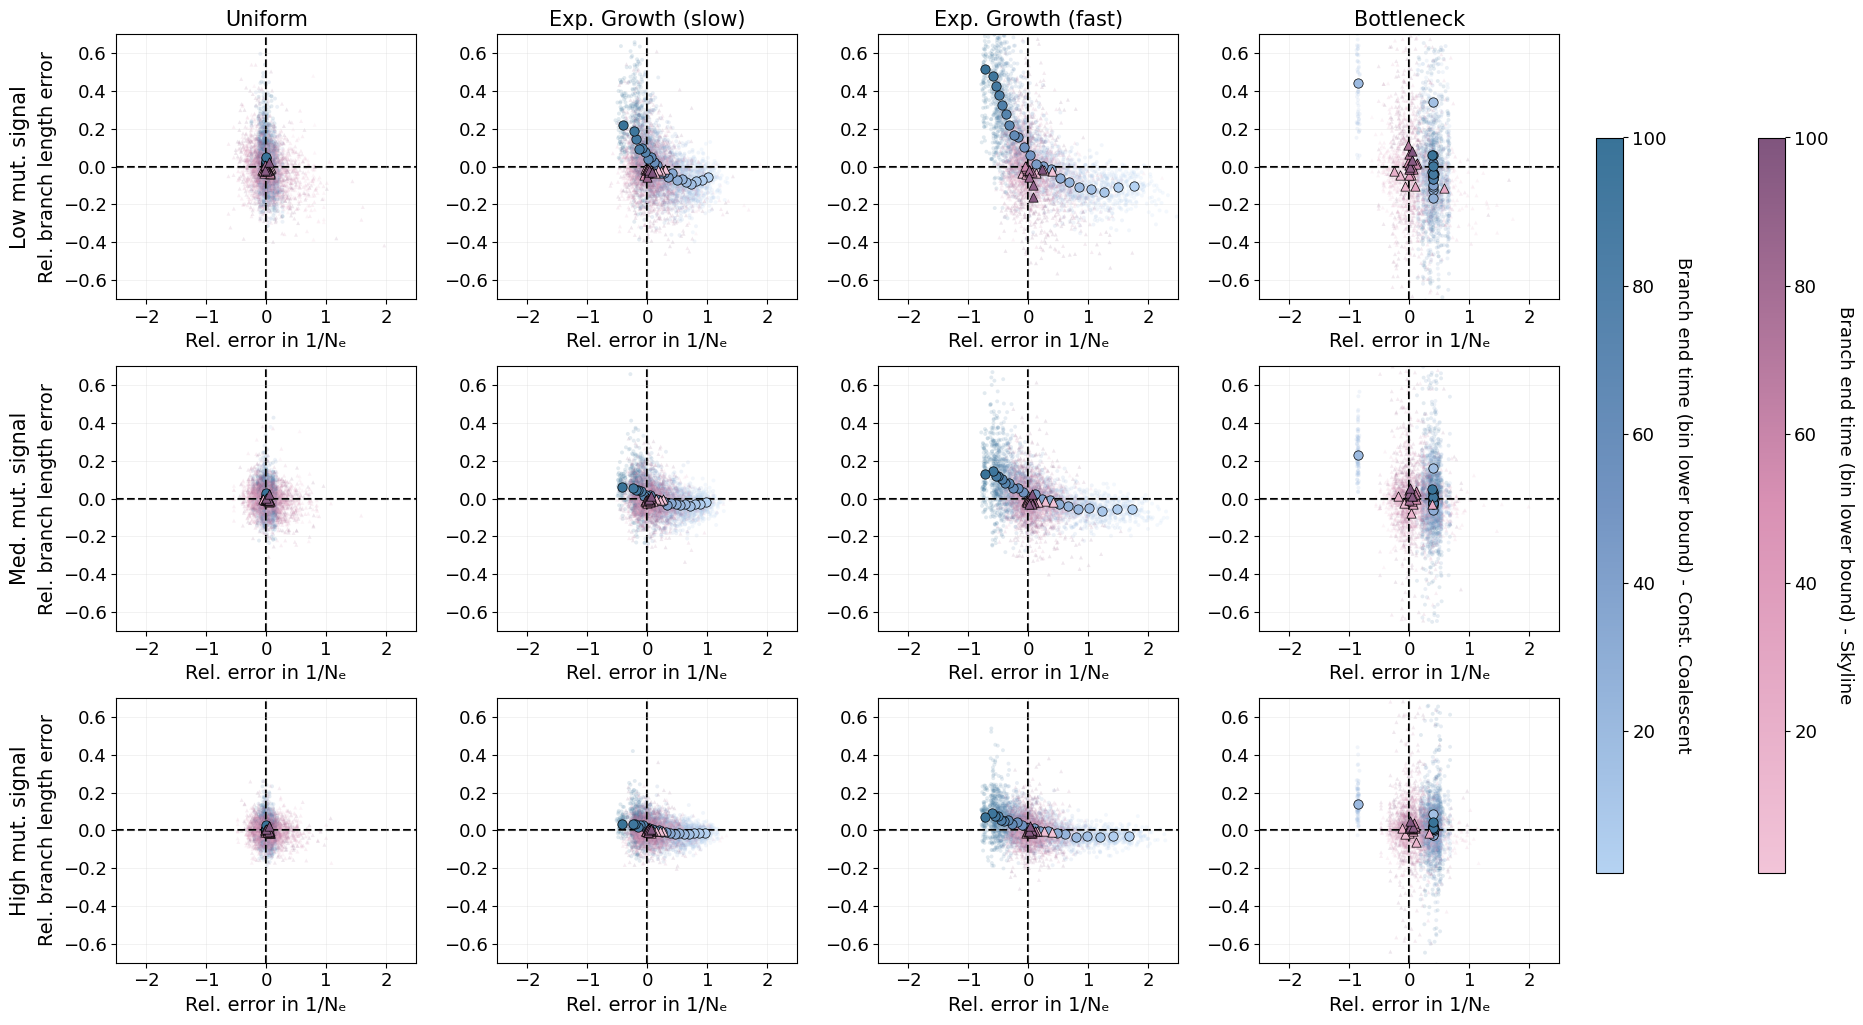

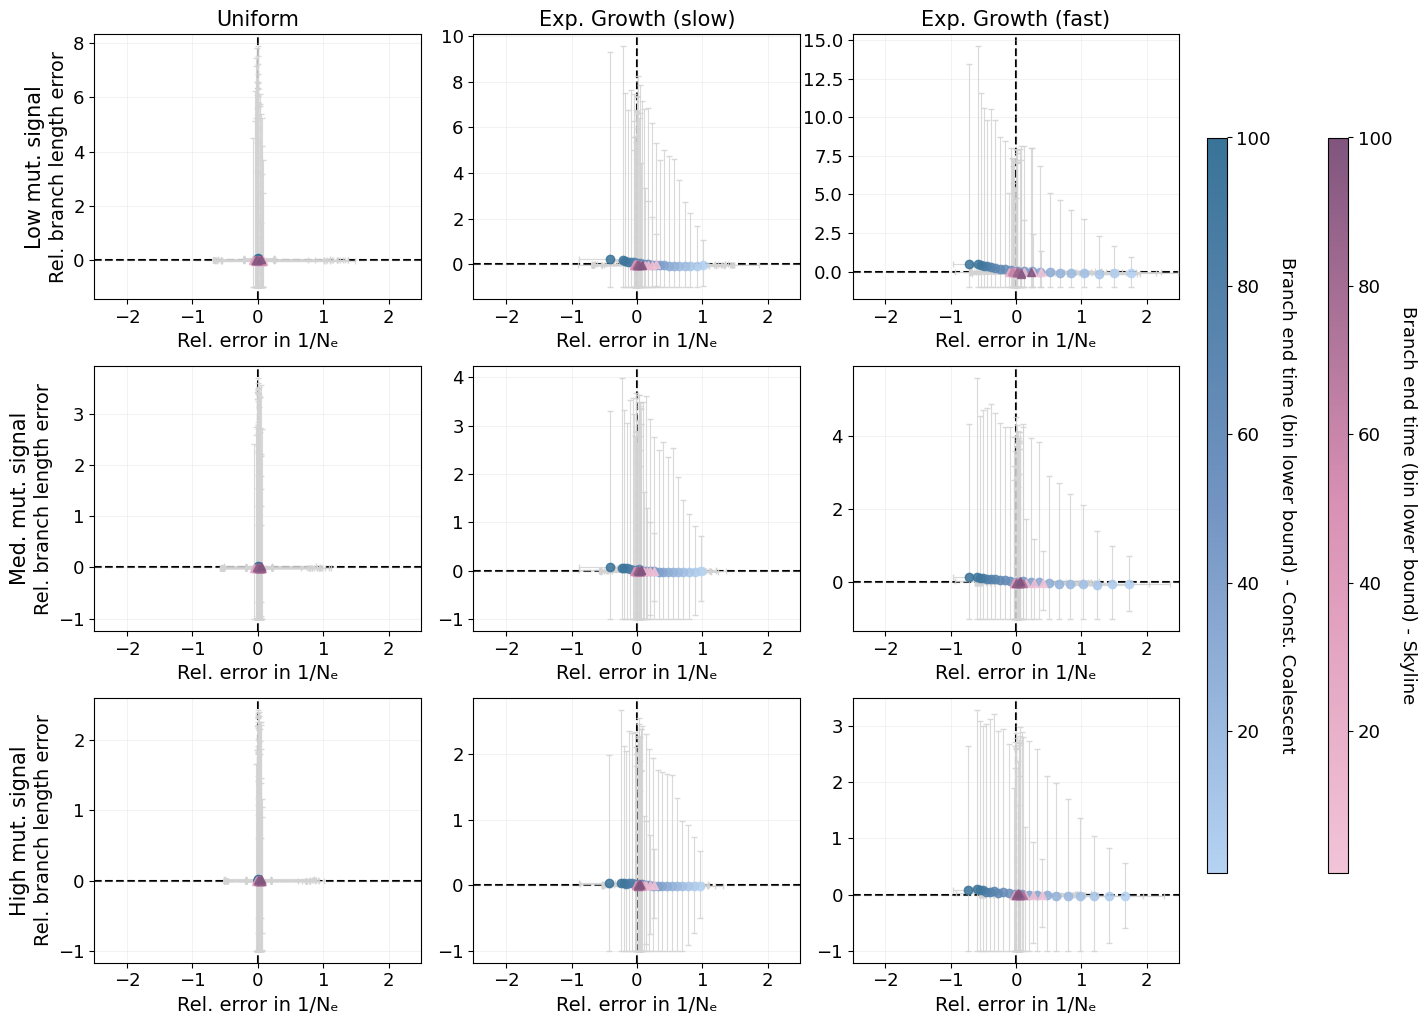

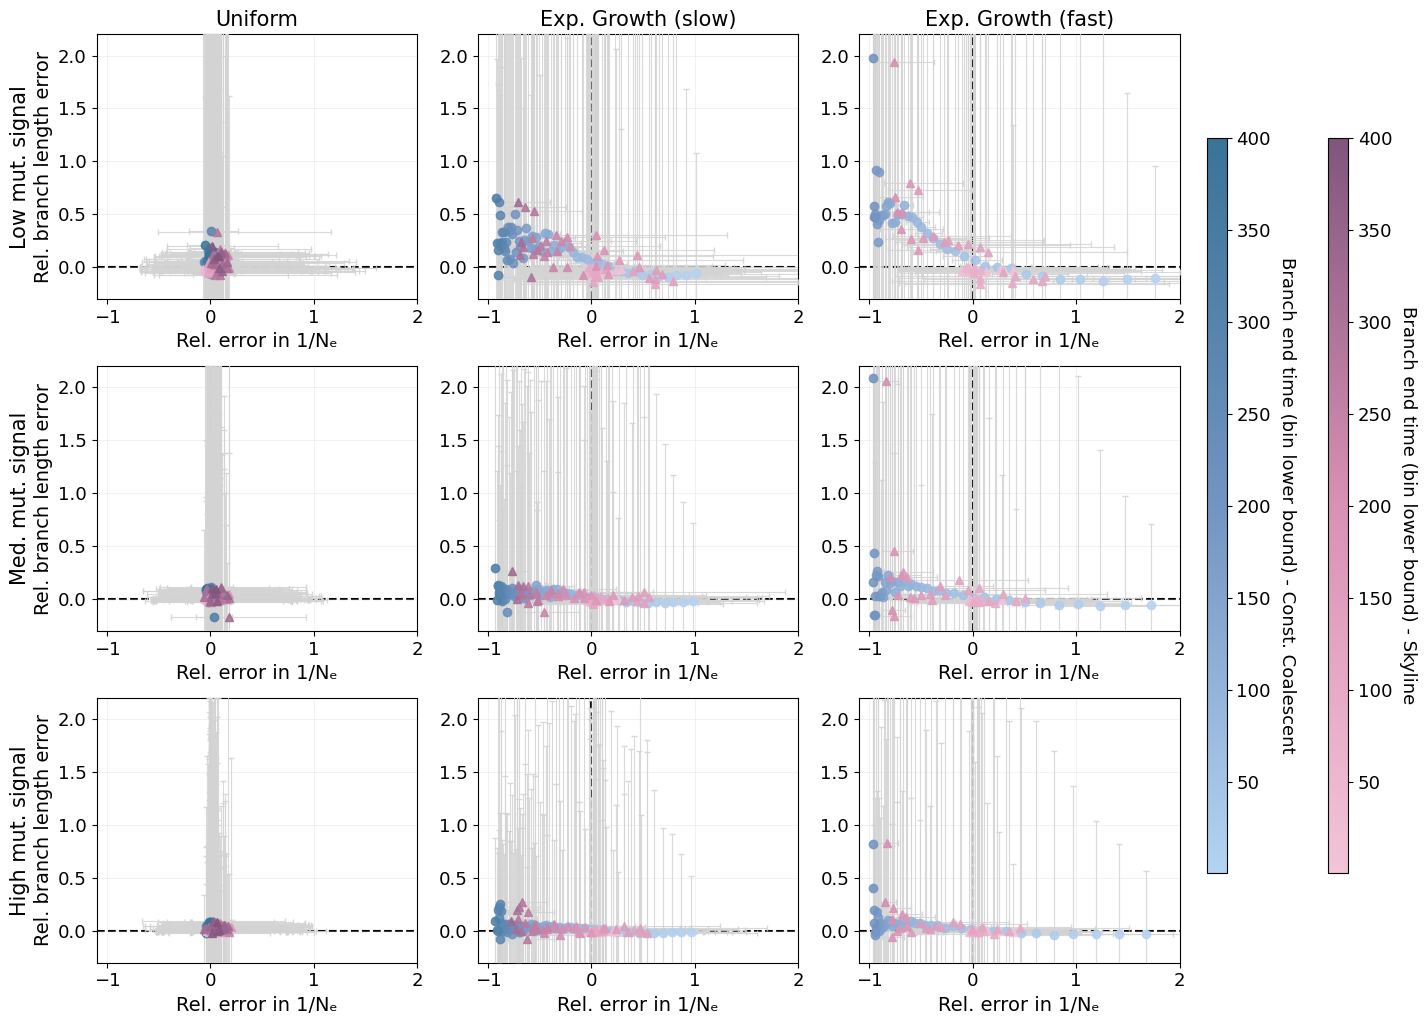

In [23]:
# heterochronous sampling, all population models, all mutation signals

# per replicate medians as background scatter
plot_binned_error_timecoloring(df_5_100, per_tree_df = df_5_100_pertree, sampling="linearconstant",
                               x_col="rate_rel_error", y_col="bl_rel_error", time_col = 'bin_lower',
                               x_range=(-2.5,2.5), y_range=(-0.7, 0.7),
                               x_label = "Rel. error in 1/Nₑ", y_label = "Rel. branch length error", title = "",
                               cbar_label_constcoal= "Branch end time (bin lower bound) - Const. Coalescent", cbar_label_skyline="Branch end time (bin lower bound) - Skyline",
                               min_nodes_per_bin=10, pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                               save_path="../figures/branch_length/time_popsize_scatter/bl_rate_error_linearconstant_pertreeuncertainty.pdf")

# showing full confidence intervals pooled over all replicates and posterior samples
plot_binned_error_timecoloring(df_5_100, sampling="linearconstant",
                               x_col="rate_rel_error", y_col="bl_rel_error", time_col = 'bin_lower',
                               x_range=(-2.5,2.5), y_range=None,
                               x_label = "Rel. error in 1/Nₑ", y_label = "Rel. branch length error", title = "",
                               cbar_label_constcoal= "Branch end time (bin lower bound) - Const. Coalescent", cbar_label_skyline="Branch end time (bin lower bound) - Skyline",
                               min_nodes_per_bin=10, pop_models=['uniform', 'expgrowthslow', 'expgrowthfast'],
                               save_path=None)

# showing 400 year time range instead of recent 100 years
plot_binned_error_timecoloring(df_5_400, sampling="linearconstant",
                               x_col="rate_rel_error", y_col="bl_rel_error", time_col = 'bin_lower',
                               x_range=(-1.1,2), y_range=(-0.3,2.2),
                               x_label = "Rel. error in 1/Nₑ", y_label = "Rel. branch length error", title = "",
                               cbar_label_constcoal= "Branch end time (bin lower bound) - Const. Coalescent", cbar_label_skyline="Branch end time (bin lower bound) - Skyline",
                               min_nodes_per_bin=10, pop_models=['uniform', 'expgrowthslow', 'expgrowthfast'],
                               save_path="../figures/branch_length/time_popsize_scatter/bl_rate_error_linearconstant_400.pdf")

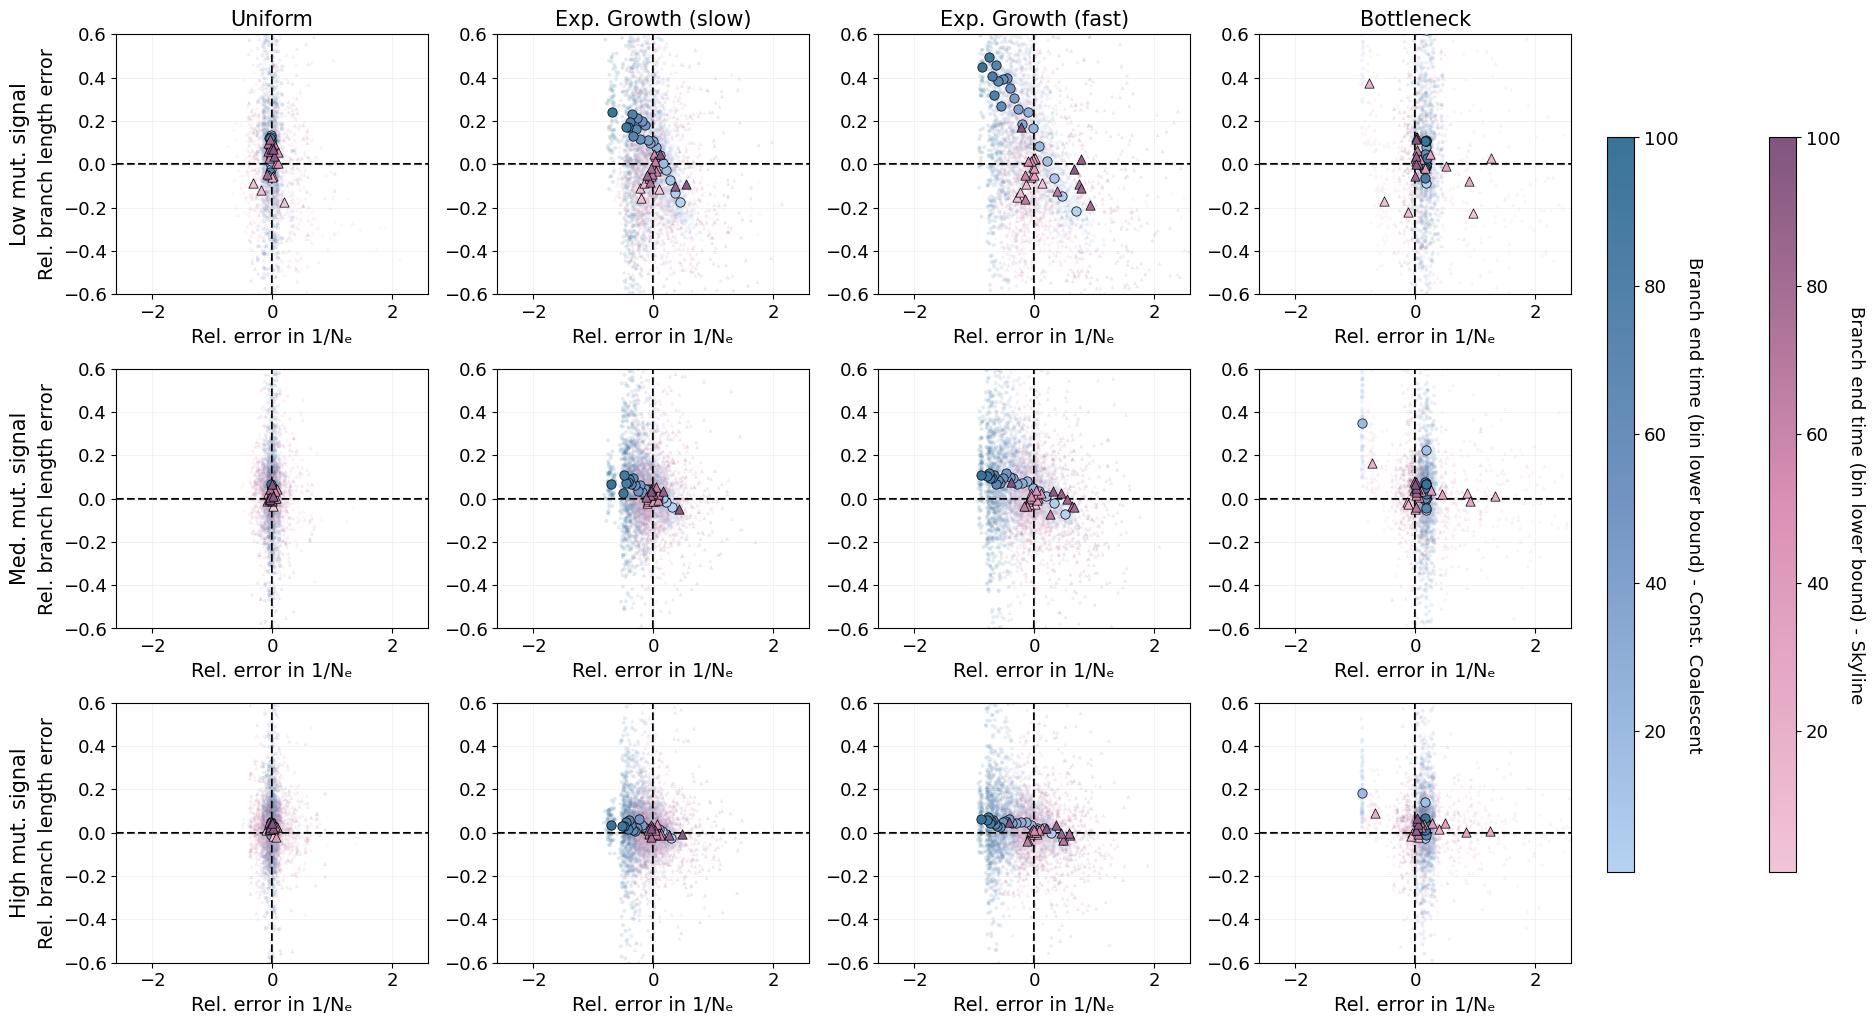

In [22]:
# homochronous sampling, all population models, all mutation signals
plot_binned_error_timecoloring(df_5_100, per_tree_df = df_5_100_pertree, sampling="independenthomochronous",
                               x_col="rate_rel_error", y_col="bl_rel_error", time_col = 'bin_lower',
                               x_range=(-2.6,2.6), y_range=(-0.6, 0.6),
                               x_label = "Rel. error in 1/Nₑ", y_label = "Rel. branch length error", title = "",
                               cbar_label_constcoal= "Branch end time (bin lower bound) - Const. Coalescent", cbar_label_skyline="Branch end time (bin lower bound) - Skyline",
                               min_nodes_per_bin=10, pop_models=['uniform', 'expgrowthslow', 'expgrowthfast', 'bottleneck'],
                               save_path="../figures/branch_length/time_popsize_scatter/bl_rate_error_independenthomochronous.pdf")

## Lineages-through-time (LTT) plots

A lineages-through-time (LTT) plot shows how many lineages a tree has at each point in time, going from the present (time 0, the youngest tip) back to the root. Reading backwards in time, the count goes down by one at
every coalescent event (internal node). Under heterochonous sampling, it also goes up by one at every sampled tip. The shape of the curve reflects the population size history. Coalescence is fast when the population is small, so
the curve drops steeply there. When the population is large, the curve stays flat.

For each scenario (population model × sampling scheme × mutation signal), we compare the LTT curve of the true simulated tree with the curves of the BEAST summary trees, inferred under the constant coalescent prior and the Bayesian skyline prior. Where an inferred curve deviates from the true one, node times are biased. This complements the per-node branch length and height errors shown above.

`compute_ltt` reads the simulated trees and the summary trees listed in `successful_mcmc_runs.csv`, and `plot_ltt` draws the curves. Under linear sampling, an arrow marks the sampling period. In the bottleneck scenario, a grey band marks the bottleneck (20–23 years before the present).

In [ ]:
# compute once and save
per_tree_df, median_df = compute_ltt(
    csv_path="../results/run1/beast_inference/successful_mcmc_runs.csv",
    sim_dir="../results/run1/simulated_data",
    sampling="linearconstant",
    pop_models=["uniform", "expgrowthslow","expgrowthfast", "bottleneck"],
    mutsigs=["low", "med", "high"],
    n_grid = 10000, grid_end = 5000,
    repo_base="../",
    out_per_tree="../results/run1/evaluation/ltt_per_tree.tsv",
    out_median="../results/run1/evaluation/ltt_median.tsv",
)

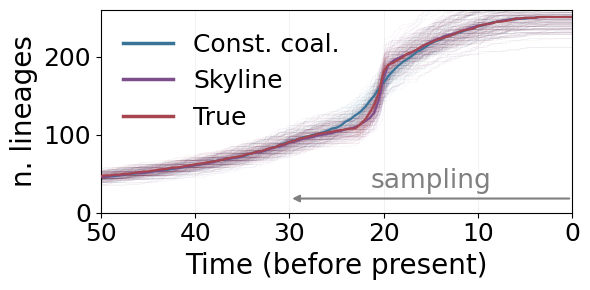

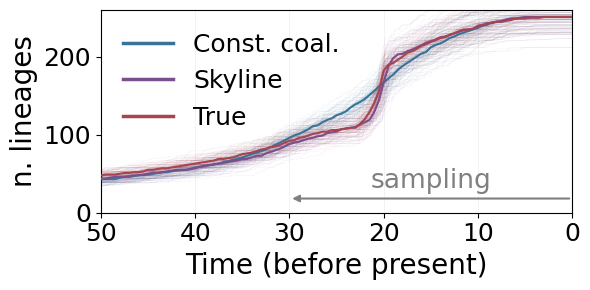

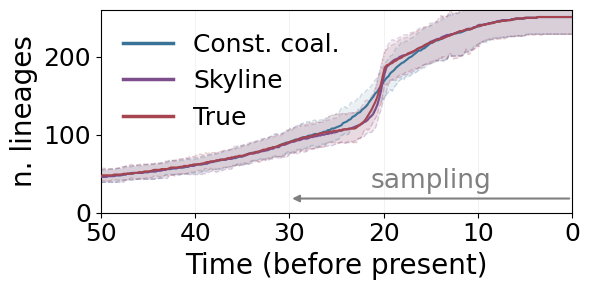

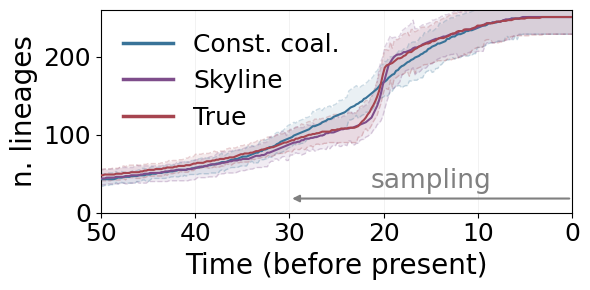

In [ ]:
# plot from saved files
per_tree_df = pd.read_csv("../results/run1/evaluation/ltt_per_tree.tsv", sep="\t")
median_df   = pd.read_csv("../results/run1/evaluation/ltt_median.tsv", sep="\t")

# plot LTT for bottleneck + linearconstant sampling
# show summary line and per tree lines
plot_ltt(per_tree_df, median_df,
        sampling="linearconstant",
        pop_models=["bottleneck"], mutsigs=["high"],
        x_range=(50, 0), y_range=(0, 260),
        alpha=0.05, linewidth=0.5, median_linewidth=1.5,
        sampling_end_time = 30, label_fontsize=20, tick_fontsize=18, legend_fontsize=18,
        save_path="../figures/ltt/ltt_bottleneck_high_linearconstant.pdf",
        figsize = (6,3))

plot_ltt(per_tree_df, median_df,
        sampling="linearconstant",
        pop_models=["bottleneck"], mutsigs=["low"],
        sampling_end_time = 30, label_fontsize=20, tick_fontsize=18, legend_fontsize=18,
        x_range=(50, 0), y_range=(0, 260),
        alpha=0.05, linewidth=0.5, median_linewidth=1.5,
        save_path="../figures/ltt/ltt_bottleneck_low_linearconstant.pdf",
        figsize = (6,3))

# show summary line with 95% HPD density band
plot_ltt(per_tree_df, median_df, mode = 'band',
        sampling="linearconstant",
        pop_models=["bottleneck"], mutsigs=["high"],
        x_range=(50, 0), y_range=(0, 260),
        alpha=0.05, linewidth=0.5, median_linewidth=1.5,
        sampling_end_time = 30, label_fontsize=20, tick_fontsize=18, legend_fontsize=18,
        save_path="../figures/ltt/ltt_bottleneck_high_linearconstant_density.pdf",
        figsize = (6,3))

plot_ltt(per_tree_df, median_df, mode = 'band',
        sampling="linearconstant",
        pop_models=["bottleneck"], mutsigs=["low"],
        sampling_end_time = 30, label_fontsize=20, tick_fontsize=18, legend_fontsize=18,
        x_range=(50, 0), y_range=(0, 260),
        alpha=0.05, linewidth=0.5, median_linewidth=1.5,
        save_path="../figures/ltt/ltt_bottleneck_low_linearconstant_density.pdf",
        figsize = (6,3))


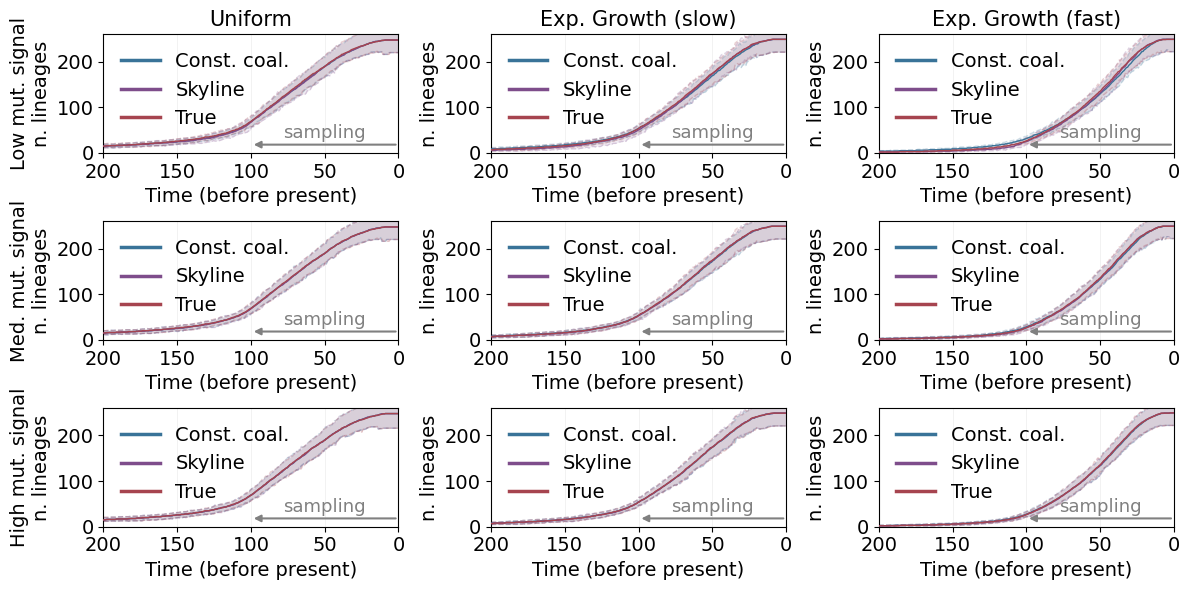

In [6]:
# ltt plots for uniform and exponential growth population models (linearconstant sampling)

plot_ltt(per_tree_df, median_df, figsize = (12,6),
        sampling="linearconstant", mode = 'band',
        pop_models=["uniform", "expgrowthslow", "expgrowthfast"], mutsigs=["low", "med", "high"],
        x_range=(200, 0), y_range=(0, 260),
        alpha=0.05, linewidth=0.5, median_linewidth=1,
        sampling_end_time = 100,
        save_path="../figures/ltt/ltt_expgrowth_linearconstant.pdf",
        )

## Pairwise tip distances

To compare how the two priors place coalescent events relative to the sampled tips, we compute pairwise tip-to-MRCA distances in the inferred trees.

### Computation
`compute_pairwise_tip_distances` uses, for each replicate, the summary trees from `treeannotator` for both priors. For every pair of tips (A, B) it finds their most recent common ancestor (MRCA) and computes the distance
from each tip to that MRCA as the difference in heights, $d_A = h_\text{MRCA} - h_A$. The heights are the median node heights (`height_median`) of the summary tree. Each pair therefore gives two distances, one per tip.
Since sampling times are fixed, they differ only when the tips were sampled at different times.

Uncertainty intervals are conservative bounds built from the 95 % HPD intervals of node and tip heights: lower $= h_\text{MRCA}^\text{lo} - h_A^\text{hi}$, upper $= h_\text{MRCA}^\text{hi} - h_A^\text{lo}$. This is done
for all replicates under heterochronous (linear) sampling, separately for each population model and mutation signal. The results are saved as one TSV per scenario.

### Plots
For the bottleneck, uniform and fast exponential growth scenarios with low mutation signal, `plot_pairwise_tip_distances` shows:
- **Scatter:** each point is one tip-to-MRCA distance, from all tip pairs and replicates. The x-axis is the skyline estimate and the y-axis is the constant-coalescent estimate, with HPD error bars. For readability, a
random subsample of 5,000 points is drawn. The dashed diagonal marks equal estimates under both priors.
- **Running median (black line):** all points (not just the subsample) are sorted by their skyline distance and split into non-overlapping windows of a fixed number of points (`window_size`). For each window, the median of
both distances is plotted.
- **Difference panel (below):** the relative difference $(d_\text{const} - d_\text{sky}) / d_\text{sky}$ for the subsampled points, with its running median per window.

For the bottleneck we additionally use `plot_pairwise_tip_distances_zoom`. It shows the full distance range (up to 2,000 years) next to a zoomed view of the most recent 50 years, each with its own subsample and window 
size. We make this figure twice: once for all tip pairs, and once restricted to pairs where **both tips were sampled less than 23 years before the present**, i.e. after the onset of the bottleneck. A third view of the 
restricted set covers distances up to 400 years.


In [ ]:
# calculate pairwise tip distances for all population models and mutation signals (low, med, high), linearconstant sampling

for pop_model in ["bottleneck", "uniform", "expgrowthfast"]:
      df = compute_pairwise_tip_distances(tree_index="all", repo_base="../", population_model=pop_model, mutation_signal = "low", sampling = "linearconstant")
      df.to_csv(f"../results/run1/evaluation/pairwise_tip_distances_{pop_model}_low_linearconstant_all_trees.tsv", sep="\t", index=False)

for pop_model in ["bottleneck", "uniform", "expgrowthfast", "expgrowthslow"]:
      df = compute_pairwise_tip_distances(tree_index="all", repo_base="../", population_model=pop_model, mutation_signal = "med", sampling = "linearconstant")
      df.to_csv(f"../results/run1/evaluation/pairwise_tip_distances_{pop_model}_med_linearconstant_all_trees.tsv", sep="\t", index=False)

for pop_model in ["bottleneck", "uniform", "expgrowthfast", "expgrowthslow"]:
      df = compute_pairwise_tip_distances(tree_index="all", repo_base="../", population_model=pop_model, mutation_signal = "high", sampling = "linearconstant")
      df.to_csv(f"../results/run1/evaluation/pairwise_tip_distances_{pop_model}_high_linearconstant_all_trees.tsv", sep="\t", index=False)

In [42]:
# load data
bottleneck_dist_df    = pd.read_csv("../results/run1/evaluation/pairwise_tip_distances_bottleneck_low_linearconstant_all_trees.tsv",    sep="\t")
uniform_dist_df       = pd.read_csv("../results/run1/evaluation/pairwise_tip_distances_uniform_low_linearconstant_all_trees.tsv",       sep="\t")
expgrowthfast_dist_df = pd.read_csv("../results/run1/evaluation/pairwise_tip_distances_expgrowthfast_low_linearconstant_all_trees.tsv", sep="\t")
expgrowthslow_dist_df = pd.read_csv("../results/run1/evaluation/pairwise_tip_distances_expgrowthslow_low_linearconstant_all_trees.tsv", sep="\t")
    
after_bottleneck_dist_df = bottleneck_dist_df[(bottleneck_dist_df['population_model'] == "bottleneck") & (bottleneck_dist_df['tip_a_time'] < 23) & (bottleneck_dist_df['tip_b_time'] < 23)]
after_bottleneck_dist_df.head()

,sampling,population_model,mutation_signal,tree_index,tip_a,tip_b,tip_a_time,tip_b_time,dist_a_constcoal_median,dist_a_constcoal_hpd_lower,...,dist_a_skyline_median,dist_a_skyline_hpd_lower,dist_a_skyline_hpd_upper,dist_b_skyline_median,dist_b_skyline_hpd_lower,dist_b_skyline_hpd_upper,dist_a_abs_diff,dist_a_rel_diff,dist_b_abs_diff,dist_b_rel_diff
0,linearconstant,bottleneck,low,1,1,70,0.0,6.1089,18.651488,14.070257,...,19.650844,17.138948,21.668352,13.541944,11.030048,15.559452,-0.999356,-0.050856,-0.999356,-0.073797
1,linearconstant,bottleneck,low,1,1,136,0.0,12.6691,18.651488,14.070257,...,19.650844,17.138948,21.668352,6.981744,4.469848,8.999252,-0.999356,-0.050856,-0.999356,-0.143138
2,linearconstant,bottleneck,low,1,1,146,0.0,13.3643,18.651488,14.070257,...,19.650844,17.138948,21.668352,6.286544,3.774648,8.304052,-0.999356,-0.050856,-0.999356,-0.158968
3,linearconstant,bottleneck,low,1,1,154,0.0,14.0951,21.049716,15.197537,...,20.063422,18.222962,23.104423,5.968322,4.127862,9.009323,0.986294,0.049159,0.986294,0.165255
4,linearconstant,bottleneck,low,1,1,164,0.0,15.6594,25.122860,16.315620,...,21.193916,18.831070,27.626033,5.534516,3.171670,11.966633,3.928945,0.185381,3.928945,0.709899


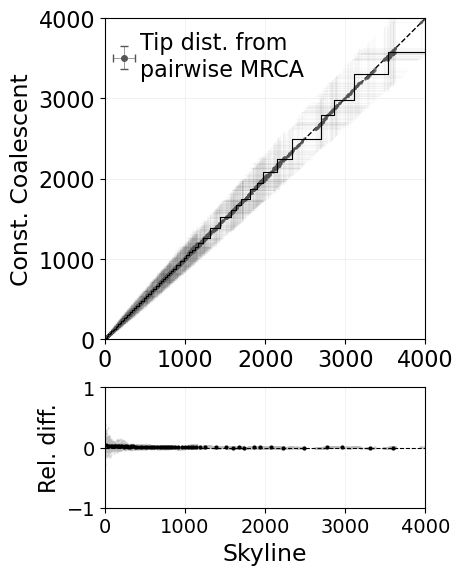

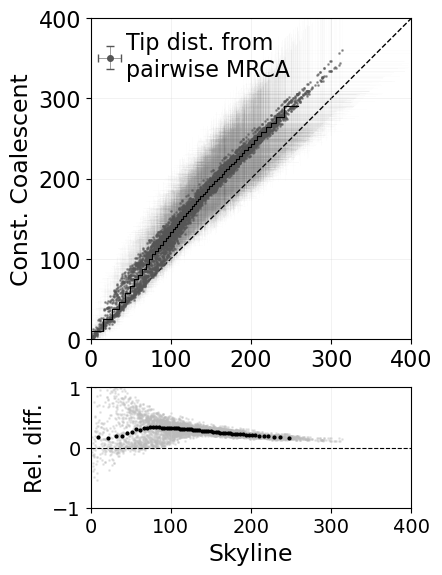

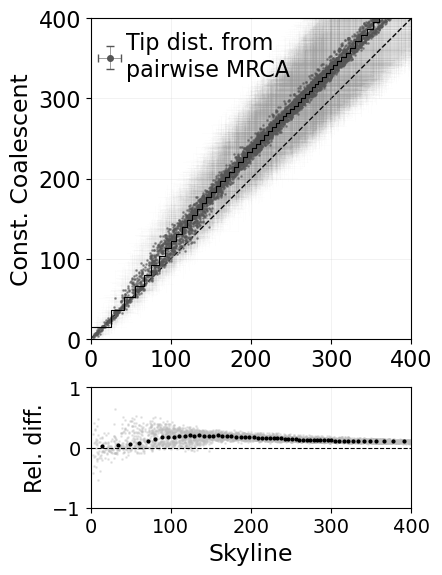

In [43]:
# heterochronous sampling

plot_pairwise_tip_distances(uniform_dist_df, sampling="linearconstant", alpha=0.5, errorbar_alpha=0.02, errorbar_width=0.5, n_subsample = 5000,
                            title = "", x_range = (0,4000), y_range = (0,4000),
                            pop_models=['uniform'], mutsigs = ['low'], figsize=(6,4), show_pop_model_labels = False, show_mutsig_labels = False,
                            running_avg=True, running_avg_color = 'black', window_size = 100000, window_overlap = 0,
                            diff_plot = "True", diff_mode = "relative", diff_axis_range = (-1, 1),
                            label_fontsize=17, tick_fontsize=16, legend_fontsize=16,
                            save_path = "../figures/branch_length/pairwise_tip_distance/pairwise_tip_distances_uniform_subsampled5000_linearconstant.pdf")

plot_pairwise_tip_distances(expgrowthfast_dist_df, sampling="linearconstant", alpha=0.5, errorbar_alpha=0.02, errorbar_width=0.5, n_subsample = 5000,
                            title = "", x_range = (0, 400), y_range = (0, 400),
                            pop_models=['expgrowthfast'], mutsigs = ['low'], figsize=(6,4), show_pop_model_labels = False, show_mutsig_labels = False,
                            running_avg=True, running_avg_color = 'black', window_size = 100000, window_overlap = 0,
                            diff_plot = "True", diff_mode = "relative", diff_axis_range = (-1,1),
                            label_fontsize=17, tick_fontsize=16, legend_fontsize=16,
                            save_path = "../figures/branch_length/pairwise_tip_distance/pairwise_tip_distances_expgrowthfast_subsampled5000_linearconstant.pdf")

plot_pairwise_tip_distances(expgrowthslow_dist_df, sampling="linearconstant", alpha=0.5, errorbar_alpha=0.02, errorbar_width=0.5, n_subsample = 5000,
                            title = "", x_range = (0, 400), y_range = (0, 400),
                            pop_models=['expgrowthslow'], mutsigs = ['low'], figsize=(6,4), show_pop_model_labels = False, show_mutsig_labels = False,
                            running_avg=True, running_avg_color = 'black', window_size = 100000, window_overlap = 0,
                            diff_plot = "True", diff_mode = "relative", diff_axis_range = (-1,1),
                            label_fontsize=17, tick_fontsize=16, legend_fontsize=16,
                            save_path = "../figures/branch_length/pairwise_tip_distance/pairwise_tip_distances_expgrowthslow_subsampled5000_linearconstant.pdf")

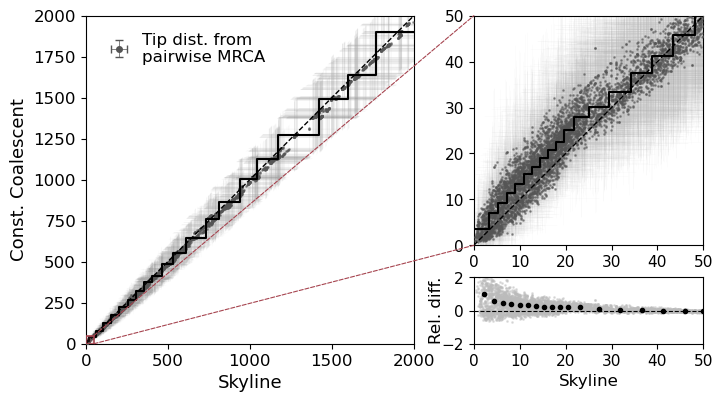

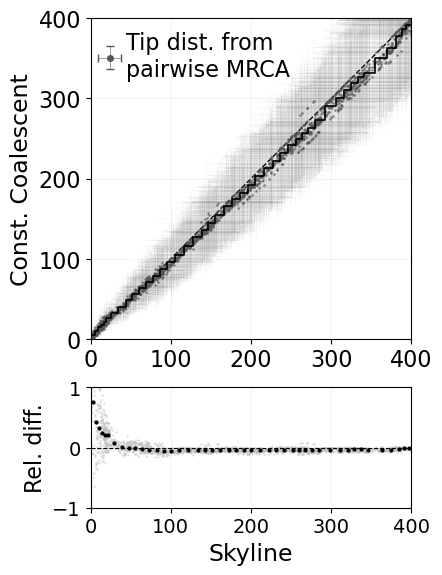

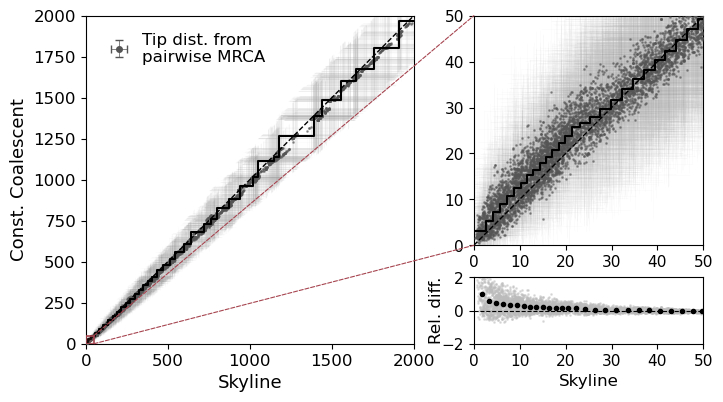

In [ ]:
# only considers tips sampled after the bottleneck event (tip times < 23), full range and zoomed in range of 50 years
plot_pairwise_tip_distances_zoom(after_bottleneck_dist_df, sampling="linearconstant",
      alpha=0.5, errorbar_alpha=0.04, errorbar_width=0.5, n_subsample=5000, n_subsample_zoom=5000,
      pop_model="bottleneck", mutsig="low",
      x_range=(0, 2000), y_range=(0, 2000),
      zoom_x_range=(0,50), zoom_y_range=(0, 50),
      figsize=(10, 4), title="", label_fontsize=13, tick_fontsize=12, legend_fontsize=12,
      running_avg=True, running_avg_color = 'black', window_size = 100000, window_overlap = 0, window_size_zoom = 10000, window_overlap_zoom = 0,
      diff_plot = "True", diff_mode = "relative", diff_axis_range = (-2,2),
      save_path="../figures/branch_length/pairwise_tip_distance/afterbottleneck_pairwise_tip_distances_bottleneck_zoom_linearconstant_reldiff.pdf",
      )

# zoomed in range of 400 years
plot_pairwise_tip_distances(after_bottleneck_dist_df, sampling="linearconstant", alpha=0.5, errorbar_alpha=0.04, errorbar_width=0.5, n_subsample = 5000,
                            title = "", x_range = (0, 400), y_range = (0, 400), running_avg_linewidth = 1.2,
                            pop_models=['bottleneck'], mutsigs = ['low'], figsize=(6,4), show_pop_model_labels = False, show_mutsig_labels = False,
                            running_avg=True, running_avg_color = 'black', window_size = 20000, window_overlap = 0,
                            diff_plot = "True", diff_mode = "relative", diff_axis_range = (-1,1),
                            label_fontsize=17, tick_fontsize=16, legend_fontsize=16,
                            save_path = "../figures/branch_length/pairwise_tip_distance/pairwise_tip_distances_bottleneck_mediumrange_linearconstant.pdf"
                            )

# all tips in bottleneck scenario
plot_pairwise_tip_distances_zoom(bottleneck_dist_df, sampling="linearconstant",
      alpha=0.5, errorbar_alpha=0.04, errorbar_width=0.5, n_subsample=5000, n_subsample_zoom=5000,
      pop_model="bottleneck", mutsig="low",
      x_range=(0, 2000), y_range=(0, 2000),
      zoom_x_range=(0,50), zoom_y_range=(0, 50),
      figsize=(10, 4), title="", label_fontsize=13, tick_fontsize=12, legend_fontsize=12,
      running_avg=True, running_avg_color = 'black', window_size = 100000, window_overlap = 0, window_size_zoom = 10000, window_overlap_zoom = 0,
      diff_plot = "True", diff_mode = "relative", diff_axis_range = (-2,2),
      save_path="../figures/branch_length/pairwise_tip_distance/bottleneck_pairwise_tip_distances_bottleneck_zoom_linearconstant_reldiff.pdf",
      )

